# AIIM 115-1 · Homework 1 — Time-Series Data Analysis: Exploring EHR Data
### PhysioNet Challenge 2012 · Predicting in-hospital mortality of ICU patients

| | |
|---|---|
| **Name** | 葉蒙恩 Farrel Jonathan Vickeldo |
| **Student ID** | R15H45018 |
| **Course** | CommE5064 Artificial Intelligence and Intelligent Medicine (2026 Fall) |
| **Assignment** | Homework 1 · due Nov 4, 2026, 23:59:59 (GMT+8) |

## Problem statement
Each ICU stay in the PhysioNet 2012 dataset has up to 48 hours of irregularly sampled measurements: 6 general descriptors recorded at admission (`RecordID`, `Age`, `Gender`, `Height`, `ICUType`, `Weight`) and 37 time-series variables (vital signs, lab values, urine output, ventilation). The label is `In-hospital_death` (1 = died in hospital, 0 = survived). **Set A** (4,000 patients) is the training set and **Set B** (4,000 patients) is the test set.

**Study design (P1):** predict at hour 36 after ICU admission, using hours 12–36 in 2-hour bins (13 bins per patient).

| Part | Task |
|---|---|
| **P1 (50%)** | Preprocessing: (a) data structure, (b) relative time conversion, (c) per-patient binned table with the provided `P12_preprocess.py`, (d) windowing to 12–36 h, (e) imputation, (f) exclusion + zero-padding to 13 bins, (g) labels + class distribution |
| **P2 (35%)** | Train a model on Set A and evaluate once on Set B. Baseline tiers (both metrics must clear): Simple AUROC ≥ 0.75 & AUPRC ≥ 0.38 · Medium ≥ 0.80 & ≥ 0.43 · Strong ≥ 0.83 & ≥ 0.46 |
| **P3 (15%)** | Open exploration: an own question about PhysioNet 2012, with approach, experiment and conclusion |

## How to run
Runs unchanged in **VS Code (local)** and **Google Colab** (Runtime → Run all; about 9 minutes). Cell 1 finds the data automatically:

| Where | Searched, in order |
|---|---|
| **Colab** | 1) files uploaded to the session (`/content`: `Homework1_Assets/`, the asset files, or `Homework1_Assets*.zip`) → 2) Google Drive: `MyDrive/<COLAB_DRIVE_SUBDIR>`, then `MyDrive`, then 3 folder levels down → 3) download `set-a`, `set-b` and the outcomes from PhysioNet |
| **Local** | `$HW1_DATA_DIR` (if set) → the notebook's folder → its parent folder |

`P12_preprocess.py` (course-provided, not on PhysioNet) is looked for next to the data, next to the notebook and in `/content`.

**Reproducibility:** final-result seed `FINAL_SEED` in cell 0. Every seed tried is written to `outputs/seed_log.csv`; library versions are printed in cell 3.

## 0 · Configuration

In [1]:
# ---- edit here ----
STUDENT_ID = "R15H45018"                    # used for output file names
COLAB_DRIVE_SUBDIR = "AIIM/HW1"             # folder inside MyDrive that holds Homework1_Assets/ or the .zip
FINAL_SEED = 42                             # seed behind the final reported result (HW rule 4)
# -------------------

import os, sys, zipfile, tarfile, importlib.util, platform
import subprocess, importlib
import lightgbm as lgb
import warnings

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import (roc_curve, precision_recall_curve, confusion_matrix, f1_score,
                             balanced_accuracy_score, accuracy_score, brier_score_loss)
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

## 1 · Environment detection and data location

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
IN_COLAB = "google.colab" in sys.modules
assert sys.version_info >= (3, 10), "P12_preprocess.py uses `X | None` type hints -> needs Python 3.10+"
import shutil, urllib.request

def notebook_dir() -> Path:
    """Folder holding this notebook (VS Code exposes it; Jupyter starts there; on Colab this is /content)."""
    vsc = globals().get("__vsc_ipynb_file__")
    return Path(vsc).resolve().parent if vsc else Path.cwd().resolve()

NB_DIR = notebook_dir()
WORK_DIR = Path("/content") if IN_COLAB else NB_DIR   # Colab: local disk, much faster than Drive for 8,000 files
WORK_DIR.mkdir(parents=True, exist_ok=True)

def has_assets(d: Path) -> bool:
    return (d / "Outcomes-a.txt").exists() and ((d / "set-a.tar.gz").exists() or (d / "set-a").is_dir())

def find_assets(roots: list[Path], depth: int = 0) -> Path | None:
    """First folder holding the data: the root itself, a Homework1_Assets/ inside it, or a Homework1_Assets*.zip.
    depth > 0 also looks that many folder levels down (used for a shallow search of Google Drive)."""
    for root in roots:
        if not root.is_dir():
            continue
        for cand in (root, root / "Homework1_Assets"):
            if has_assets(cand):
                return cand.resolve()
        zips = sorted(root.glob("Homework1_Assets*.zip"))
        if zips:
            print(f"Unzipping {zips[0]} ...")
            with zipfile.ZipFile(zips[0]) as z:
                z.extractall(WORK_DIR)
            if has_assets(WORK_DIR / "Homework1_Assets"):
                return WORK_DIR / "Homework1_Assets"
        if depth > 0:
            found = find_assets(sorted(p for p in root.iterdir() if p.is_dir() and not p.name.startswith(".")), depth - 1)
            if found:
                return found
    return None

def download_from_physionet(dest: Path) -> Path:
    """Last resort: the four data files are public on PhysioNet (P12_preprocess.py is not - it must be uploaded)."""
    base = "https://physionet.org/files/challenge-2012/1.0.0/"
    for name in ["set-a.tar.gz", "set-b.tar.gz", "Outcomes-a.txt", "Outcomes-b.txt"]:
        if not (dest / name).exists():
            print(f"Downloading {name} from PhysioNet ...")
            urllib.request.urlretrieve(base + name, dest / name)
    return dest

if IN_COLAB:
    # 1) files uploaded to the Colab session, 2) Google Drive, 3) download from PhysioNet
    ASSETS = find_assets([Path("/content"), WORK_DIR])
    if ASSETS is None:
        from google.colab import drive
        drive.mount("/content/drive")
        my_drive = Path("/content/drive/MyDrive")
        ASSETS = find_assets([my_drive / COLAB_DRIVE_SUBDIR, my_drive]) or find_assets([my_drive], depth=3)
    if ASSETS is None:
        ASSETS = download_from_physionet(WORK_DIR)
    if not str(ASSETS).startswith(str(WORK_DIR)):              # copy the archives off Drive before extracting
        for f in ASSETS.iterdir():
            if f.is_file() and not (WORK_DIR / f.name).exists():
                shutil.copy2(f, WORK_DIR / f.name)
        ASSETS = WORK_DIR
else:
    env_dir = os.environ.get("HW1_DATA_DIR")
    roots = ([Path(env_dir)] if env_dir else []) + [NB_DIR, NB_DIR.parent]
    ASSETS = find_assets(roots)
    if ASSETS is None:
        raise FileNotFoundError(f"No Homework1_Assets folder or zip found in {[str(r) for r in roots]}. "
                                "Put Homework1_Assets/ next to this notebook (or one level up), or set HW1_DATA_DIR.")
DATA_DIR = ASSETS

# P12_preprocess.py (course-provided) must sit in DATA_DIR - look next to the data, the notebook and in /content
if not (DATA_DIR / "P12_preprocess.py").exists():
    search = [NB_DIR, Path("/content"), Path("/content/drive/MyDrive") / COLAB_DRIVE_SUBDIR]
    src = next((d / "P12_preprocess.py" for d in search if (d / "P12_preprocess.py").exists()), None)
    assert src is not None, "P12_preprocess.py not found: upload it to /content (Colab) or put it next to this notebook"
    shutil.copy2(src, DATA_DIR / "P12_preprocess.py")

print(f"Platform : {'Colab' if IN_COLAB else platform.system() + ' (local)'} | Python {platform.python_version()}")
print(f"DATA_DIR : {DATA_DIR}")

Platform : Colab | Python 3.13.16
DATA_DIR : /content/drive/MyDrive/01. SMHI/02. 1st Semester/CommE5064 Artificial Intelligence and Intelligent Medicine/Homeworks/HW1/hw1_R15H45018


## 2 · Extract set-a / set-b (skipped if already extracted)

In [4]:
def extract_if_needed(name: str) -> None:
    target, archive = DATA_DIR / name, DATA_DIR / f"{name}.tar.gz"
    if target.exists() and any(target.glob("*.txt")):
        return
    print(f"Extracting {archive.name} ...")
    with tarfile.open(archive) as tar:
        if sys.version_info >= (3, 12):
            tar.extractall(DATA_DIR, filter="data")   # safe extraction (no path traversal)
        else:
            tar.extractall(DATA_DIR)

for s in ["set-a", "set-b"]:
    extract_if_needed(s)

SET_A_DIR, SET_B_DIR = DATA_DIR / "set-a", DATA_DIR / "set-b"
OUTCOMES_A, OUTCOMES_B = DATA_DIR / "Outcomes-a.txt", DATA_DIR / "Outcomes-b.txt"
OUT_DIR = DATA_DIR / "outputs"; OUT_DIR.mkdir(exist_ok=True)

n_a, n_b = len(list(SET_A_DIR.glob("*.txt"))), len(list(SET_B_DIR.glob("*.txt")))
print(f"set-a: {n_a} files | set-b: {n_b} files")
assert n_a == 4000 and n_b == 4000, "Expected 4,000 patient files per set"

set-a: 4000 files | set-b: 4000 files


## 3 · Libraries, device, seeds, seed log

In [5]:
def ensure(pkg, import_name=None):
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        cmd = [sys.executable, "-m", "pip", "install", "-q", pkg]
        if subprocess.call(cmd, stderr=subprocess.DEVNULL) != 0:                      # system Python (PEP 668) refuses plain installs
            subprocess.check_call(cmd + ["--break-system-packages"])

for pkg, mod in [("numpy", None), ("pandas", None), ("scikit-learn", "sklearn"),
                 ("matplotlib", None), ("lightgbm", None)]:
    ensure(pkg, mod)

import random, csv, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    torch, DEVICE = None, "cpu (torch not installed)"
print("Device:", DEVICE)

def set_seed(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    if torch is not None:
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

SEED_LOG = OUT_DIR / "seed_log.csv"
def log_seed(seed: int, experiment: str, **metrics) -> None:
    """Append every seed you try (HW rule 4 requires reporting all of them)."""
    new = not SEED_LOG.exists()
    with open(SEED_LOG, "a", newline="") as f:
        w = csv.writer(f)
        if new: w.writerow(["time", "seed", "experiment", "metrics"])
        w.writerow([datetime.datetime.now().isoformat(timespec="seconds"), seed, experiment, metrics])

set_seed(FINAL_SEED)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)

# Library versions used for this run (report them - results can differ slightly between versions)
from importlib.metadata import version, PackageNotFoundError
def _v(pkg):
    try: return version(pkg)
    except PackageNotFoundError: return "-"
print(f"Python {platform.python_version()} | " + " | ".join(f"{p} {_v(p)}" for p in
      ["numpy", "pandas", "scikit-learn", "lightgbm", "matplotlib", "torch"]))

Device: cuda
Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | lightgbm 4.6.0 | matplotlib 3.10.0 | torch 2.11.0+cu130


## 4 · Import the provided `P12_preprocess.py` + sanity check

In [6]:
# Import from DATA_DIR so its internal `Path(__file__).parent` points at set-a/, set-b/, Outcomes-*.txt
spec = importlib.util.spec_from_file_location("p12", DATA_DIR / "P12_preprocess.py")
p12 = importlib.util.module_from_spec(spec); spec.loader.exec_module(p12)

outcomes_a, outcomes_b = p12.load_outcomes(OUTCOMES_A), p12.load_outcomes(OUTCOMES_B)
demo = p12.process_patient(SET_A_DIR / "132539.txt", outcomes_a)
print("outcomes:", len(outcomes_a), len(outcomes_b), "| demo patient wide table:", demo.shape)
demo.head(3)

outcomes: 4000 4000 | demo patient wide table: (24, 45)


Parameter,pid,timestamp,Weight,ALP,ALT,AST,Albumin,BUN,Bilirubin,Cholesterol,Creatinine,DiasABP,FiO2,GCS,Glucose,HCO3,HCT,HR,K,Lactate,MAP,MechVent,Mg,NIDiasABP,NIMAP,NISysABP,Na,PaCO2,PaO2,Platelets,RespRate,SaO2,SysABP,Temp,TroponinI,TroponinT,Urine,WBC,pH,Age,Height,Gender,ICUType,target,seg_entry_cnt
0,132539,2,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,70.0,NaN,NaN,NaN,NaN,NaN,61.666667,90.11,147.0,NaN,NaN,NaN,NaN,18.666667,NaN,NaN,35.35,NaN,NaN,330.0,NaN,NaN,54.0,NaN,0.0,4.0,0,4
1,132539,4,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,33.7,71.0,NaN,NaN,NaN,NaN,NaN,52.000000,74.17,118.5,NaN,NaN,NaN,NaN,19.500000,NaN,NaN,37.80,NaN,NaN,115.0,NaN,NaN,54.0,NaN,0.0,4.0,0,3
2,132539,6,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,73.5,NaN,NaN,NaN,NaN,NaN,45.000000,66.67,110.0,NaN,NaN,NaN,NaN,18.500000,NaN,NaN,NaN,NaN,NaN,170.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2


## P1(a) · Data structure

In [7]:
# P1(a) · Load one patient record from set-a/ with pandas
patient_file = SET_A_DIR / "132539.txt"

patient_raw = pd.read_csv(patient_file)         # the file exactly as stored, RecordID row included

print("Source file :", patient_file.name)
print("Shape       :", patient_raw.shape)
patient_raw.head(3)

Source file : 132539.txt
Shape       : (273, 3)


,Time,Parameter,Value
0,00:00,RecordID,132539.0
1,00:00,Age,54.0
2,00:00,Gender,0.0


In this project, we use the data given by the TA. Therefore, every data access will use local dataset. Here, we try to pick a patient with `RecordID = 132539` by accessing `132539.txt` and we find three columns.
1. **Time** : how long after ICU admission each measurement was taken, as HH:MM (hours:minutes), not the time of day.
2. **Parameter**, based on the PhysioNet page, the file starts with 6 general descriptors at 00:00, followed by variables measured repeatedly.
3. **Value**: each parameter has a fixed unit, valid values are non-negative, and -1 means missing or unknown (only in descriptors).

## P1(b) · Relative time conversion

In [8]:
# P1(b) · Convert the "HH:MM" time format to hours as a float
def hhmm_to_hours(time_string: str) -> float:
    hours, minutes = time_string.split(":")  # "01:30" -> "01" and "30"
    return int(hours) + int(minutes) / 60     # 1 + 30/60 = 1.5 hours

# Change the time column from "HH:MM" format to hours as a float
patient_hours = patient_raw.copy()
patient_hours["Time"] = patient_hours["Time"].apply(hhmm_to_hours)  # convert Time column to hours
# Save the change to a new file
patient_hours.to_csv(OUT_DIR / "132539_hours.txt", index=False)   # index=False to avoid make new index

We create a function to convert `hh:mm` format to a numeric hour count. First, we create a function to convert it, then use pandas.dataFrame.apply() to apply the function on the `Time` column. Lastly, we save the modified df to a new file.

## P1(c) · Per-patient time series structure (provided code)

In [9]:
# P1(c) · Process one patient record to get the wide table
# Pass all of patient records to the process_patient function to get the wide table
wide_a = p12.process_set(SET_A_DIR, OUTCOMES_A)
wide_b = p12.process_set(SET_B_DIR, OUTCOMES_B)

# We check only in wide_a for the same patient (pid=132539) to see if it matches the raw data
# Raw data: one patient, long format (one row per measurement)
print("Raw:", patient_raw.shape)
display(patient_raw.head(15))

# Processed data: the same patient, from the run on all patients
one_wide = wide_a[wide_a["pid"] == 132539]
print("Processed:", one_wide.shape)
display(one_wide)

Raw: (273, 3)


,Time,Parameter,Value
0,00:00,RecordID,132539.00
1,00:00,Age,54.00
2,00:00,Gender,0.00
3,00:00,Height,-1.00
4,00:00,ICUType,4.00
5,00:00,Weight,-1.00
6,00:07,GCS,15.00
7,00:07,HR,73.00
8,00:07,NIDiasABP,65.00
9,00:07,NIMAP,92.33


Processed: (24, 45)


Parameter,pid,timestamp,Weight,ALP,ALT,AST,Albumin,BUN,Bilirubin,Cholesterol,Creatinine,DiasABP,FiO2,GCS,Glucose,HCO3,HCT,HR,K,Lactate,MAP,MechVent,Mg,NIDiasABP,NIMAP,NISysABP,Na,PaCO2,PaO2,Platelets,RespRate,SaO2,SysABP,Temp,TroponinI,TroponinT,Urine,WBC,pH,Age,Height,Gender,ICUType,target,seg_entry_cnt
0,132539,2,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,70.0,NaN,NaN,NaN,NaN,NaN,61.666667,90.110,147.0,NaN,NaN,NaN,NaN,18.666667,NaN,NaN,35.35,NaN,NaN,330.0,NaN,NaN,54.0,NaN,0.0,4.0,0,4
1,132539,4,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,33.7,71.0,NaN,NaN,NaN,NaN,NaN,52.000000,74.170,118.5,NaN,NaN,NaN,NaN,19.500000,NaN,NaN,37.80,NaN,NaN,115.0,NaN,NaN,54.0,NaN,0.0,4.0,0,3
2,132539,6,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,73.5,NaN,NaN,NaN,NaN,NaN,45.000000,66.670,110.0,NaN,NaN,NaN,NaN,18.500000,NaN,NaN,NaN,NaN,NaN,170.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
3,132539,8,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,64.0,NaN,NaN,NaN,NaN,NaN,49.000000,68.330,107.0,NaN,NaN,NaN,NaN,15.000000,NaN,NaN,38.10,NaN,NaN,120.0,NaN,NaN,54.0,NaN,0.0,4.0,0,1
4,132539,10,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.0,NaN,NaN,NaN,NaN,NaN,52.000000,70.665,108.0,NaN,NaN,NaN,NaN,15.500000,NaN,NaN,NaN,NaN,NaN,90.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
5,132539,12,-1.0,NaN,NaN,NaN,NaN,13.0,NaN,NaN,0.8,NaN,NaN,15.0,205.0,26.0,33.5,59.5,4.4,NaN,NaN,NaN,1.5,51.000000,69.000,105.0,137.0,NaN,NaN,221.0,15.000000,NaN,NaN,37.60,NaN,NaN,70.0,11.2,NaN,54.0,NaN,0.0,4.0,0,2
6,132539,14,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.0,NaN,NaN,NaN,NaN,NaN,43.500000,63.000,102.0,NaN,NaN,NaN,NaN,13.500000,NaN,NaN,NaN,NaN,NaN,55.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
7,132539,16,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,66.0,NaN,NaN,NaN,NaN,NaN,49.000000,70.000,112.0,NaN,NaN,NaN,NaN,13.500000,NaN,NaN,36.90,NaN,NaN,120.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
8,132539,18,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,63.0,NaN,NaN,NaN,NaN,NaN,41.500000,60.000,97.0,NaN,NaN,NaN,NaN,13.500000,NaN,NaN,NaN,NaN,NaN,140.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
9,132539,20,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,68.5,NaN,NaN,NaN,NaN,NaN,55.000000,74.670,114.0,NaN,NaN,NaN,NaN,15.500000,NaN,NaN,37.30,NaN,NaN,80.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2


According to the Physionet documentation, there are 6 general descriptors and 37 time-series variable. Since the general descriptors are static, these variables are copied onto every row. When the data is structured to have each features as the column, we will see many value in a bin that has no observed value (expressed as 'NaN'). To handle, this we use `P12_preprocess.py` to help preprocess our data and copies the static descriptors onto every row. Here, we also set the `Time` into the bin to reduce the resolution, changing the numeric hour count with `BIN_HOURS = 2`.

In the `patient_raw` dataframe, we have six general descriptors and 37 time-series variables. After transforming using `process_set(SET_PATH, OUTCOMES_PATH)`, we have 24 rows and 45 columns. We remove `RecordID` and we delete duplicated `Weight` features, leaving only four descriptors, and 37 time-series variable. Here, we engineers four new columns:
1. `pid`, taken from the `RecordID`
2. `timestamp`, taken from the end of converting Time format
3. `target`, the label `In-hospital_death` from OUTCOMES: 1 = died in hospital, 0 = survived.
4. `seg_entry_cnt`, the number of **distinct raw time points** merge into that bin to quantize the time and fit the resolution.

## P1(d) · Windowing 12 ≤ t ≤ 36

In [10]:
# P1(d) · Keep only bins inside the input window, 12 <= timestamp <= 36 (both ends inclusive)
WINDOW_START, WINDOW_END = 12, 36

def apply_window(wide: pd.DataFrame) -> pd.DataFrame:
    in_window = (wide["timestamp"] >= WINDOW_START) & (wide["timestamp"] <= WINDOW_END)
    return wide[in_window].copy()

wide_a_windowed = apply_window(wide_a)
wide_b_windowed = apply_window(wide_b)

one_windowed = wide_a_windowed[wide_a_windowed["pid"] == 132539]

print("Before window (patient 132539):", one_wide.shape)
display(one_wide)

print("After window (patient 132539):", one_windowed.shape)
print("Timestamps kept:", sorted(one_windowed["timestamp"].unique()))
display(one_windowed)

print(f"Set A: {wide_a.shape} -> {wide_a_windowed.shape} | Set B: {wide_b.shape} -> {wide_b_windowed.shape}")

Before window (patient 132539): (24, 45)


Parameter,pid,timestamp,Weight,ALP,ALT,AST,Albumin,BUN,Bilirubin,Cholesterol,Creatinine,DiasABP,FiO2,GCS,Glucose,HCO3,HCT,HR,K,Lactate,MAP,MechVent,Mg,NIDiasABP,NIMAP,NISysABP,Na,PaCO2,PaO2,Platelets,RespRate,SaO2,SysABP,Temp,TroponinI,TroponinT,Urine,WBC,pH,Age,Height,Gender,ICUType,target,seg_entry_cnt
0,132539,2,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,70.0,NaN,NaN,NaN,NaN,NaN,61.666667,90.110,147.0,NaN,NaN,NaN,NaN,18.666667,NaN,NaN,35.35,NaN,NaN,330.0,NaN,NaN,54.0,NaN,0.0,4.0,0,4
1,132539,4,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,33.7,71.0,NaN,NaN,NaN,NaN,NaN,52.000000,74.170,118.5,NaN,NaN,NaN,NaN,19.500000,NaN,NaN,37.80,NaN,NaN,115.0,NaN,NaN,54.0,NaN,0.0,4.0,0,3
2,132539,6,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,73.5,NaN,NaN,NaN,NaN,NaN,45.000000,66.670,110.0,NaN,NaN,NaN,NaN,18.500000,NaN,NaN,NaN,NaN,NaN,170.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
3,132539,8,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,64.0,NaN,NaN,NaN,NaN,NaN,49.000000,68.330,107.0,NaN,NaN,NaN,NaN,15.000000,NaN,NaN,38.10,NaN,NaN,120.0,NaN,NaN,54.0,NaN,0.0,4.0,0,1
4,132539,10,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.0,NaN,NaN,NaN,NaN,NaN,52.000000,70.665,108.0,NaN,NaN,NaN,NaN,15.500000,NaN,NaN,NaN,NaN,NaN,90.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
5,132539,12,-1.0,NaN,NaN,NaN,NaN,13.0,NaN,NaN,0.8,NaN,NaN,15.0,205.0,26.0,33.5,59.5,4.4,NaN,NaN,NaN,1.5,51.000000,69.000,105.0,137.0,NaN,NaN,221.0,15.000000,NaN,NaN,37.60,NaN,NaN,70.0,11.2,NaN,54.0,NaN,0.0,4.0,0,2
6,132539,14,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.0,NaN,NaN,NaN,NaN,NaN,43.500000,63.000,102.0,NaN,NaN,NaN,NaN,13.500000,NaN,NaN,NaN,NaN,NaN,55.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
7,132539,16,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,66.0,NaN,NaN,NaN,NaN,NaN,49.000000,70.000,112.0,NaN,NaN,NaN,NaN,13.500000,NaN,NaN,36.90,NaN,NaN,120.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
8,132539,18,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,63.0,NaN,NaN,NaN,NaN,NaN,41.500000,60.000,97.0,NaN,NaN,NaN,NaN,13.500000,NaN,NaN,NaN,NaN,NaN,140.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
9,132539,20,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,68.5,NaN,NaN,NaN,NaN,NaN,55.000000,74.670,114.0,NaN,NaN,NaN,NaN,15.500000,NaN,NaN,37.30,NaN,NaN,80.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2


After window (patient 132539): (13, 45)
Timestamps kept: [np.int64(12), np.int64(14), np.int64(16), np.int64(18), np.int64(20), np.int64(22), np.int64(24), np.int64(26), np.int64(28), np.int64(30), np.int64(32), np.int64(34), np.int64(36)]


Parameter,pid,timestamp,Weight,ALP,ALT,AST,Albumin,BUN,Bilirubin,Cholesterol,Creatinine,DiasABP,FiO2,GCS,Glucose,HCO3,HCT,HR,K,Lactate,MAP,MechVent,Mg,NIDiasABP,NIMAP,NISysABP,Na,PaCO2,PaO2,Platelets,RespRate,SaO2,SysABP,Temp,TroponinI,TroponinT,Urine,WBC,pH,Age,Height,Gender,ICUType,target,seg_entry_cnt
5,132539,12,-1.0,NaN,NaN,NaN,NaN,13.0,NaN,NaN,0.8,NaN,NaN,15.0,205.0,26.0,33.5,59.5,4.4,NaN,NaN,NaN,1.5,51.0,69.00,105.0,137.0,NaN,NaN,221.0,15.0,NaN,NaN,37.6,NaN,NaN,70.0,11.2,NaN,54.0,NaN,0.0,4.0,0,2
6,132539,14,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.0,NaN,NaN,NaN,NaN,NaN,43.5,63.00,102.0,NaN,NaN,NaN,NaN,13.5,NaN,NaN,NaN,NaN,NaN,55.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
7,132539,16,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,66.0,NaN,NaN,NaN,NaN,NaN,49.0,70.00,112.0,NaN,NaN,NaN,NaN,13.5,NaN,NaN,36.9,NaN,NaN,120.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
8,132539,18,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,63.0,NaN,NaN,NaN,NaN,NaN,41.5,60.00,97.0,NaN,NaN,NaN,NaN,13.5,NaN,NaN,NaN,NaN,NaN,140.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
9,132539,20,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,68.5,NaN,NaN,NaN,NaN,NaN,55.0,74.67,114.0,NaN,NaN,NaN,NaN,15.5,NaN,NaN,37.3,NaN,NaN,80.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
10,132539,22,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,67.5,NaN,NaN,NaN,NaN,NaN,44.0,63.33,102.0,NaN,NaN,NaN,NaN,16.0,NaN,NaN,NaN,NaN,NaN,70.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
11,132539,24,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,68.5,NaN,NaN,NaN,NaN,NaN,41.5,62.17,103.5,NaN,NaN,NaN,NaN,19.5,NaN,NaN,37.1,NaN,NaN,60.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
12,132539,26,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,67.0,NaN,NaN,NaN,NaN,NaN,48.0,67.00,105.0,NaN,NaN,NaN,NaN,16.0,NaN,NaN,NaN,NaN,NaN,115.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
13,132539,28,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,80.0,NaN,NaN,NaN,NaN,NaN,39.0,60.67,104.0,NaN,NaN,NaN,NaN,18.5,NaN,NaN,37.9,NaN,NaN,200.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2
14,132539,30,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,NaN,NaN,NaN,NaN,41.0,63.33,108.0,NaN,NaN,NaN,NaN,16.0,NaN,NaN,NaN,NaN,NaN,90.0,NaN,NaN,54.0,NaN,0.0,4.0,0,2


Set A: (93698, 45) -> (50805, 45) | Set B: (93685, 45) -> (50777, 45)


We decide to put a window to the record in hour 12 until hour 36.

**Why begin observation at hour 12 rather than 0?**
Initiating the data collection at the twelfth hour isolates the patient's intrinsic condition from early intervention effects. The initial timeframe reflects the immediate post-procedure phase and acute stabilization protocols rather than the underlying disease progression. For instance, in Cardiac Surgery Recovery units, consciousness scores (GCS) are artificially low in the first few hours due to anesthetic wear-off, a factor that improves significantly by hour 12 and continues rising over time; early low scores indicate anesthesia rather than neurological injury. Additionally, admission triggers frequent laboratory testing—averaging 2.8 values per bin in the first four hours versus just 1.8 at hour 12—and high rates of mechanical ventilation (35–37% during hours 4–6). These figures drop to roughly 25% by hour 36 as patients stabilize and are weaned off machines. Therefore, the first twelve hours are dominated by therapeutic processes rather than patient baseline data; they represent a distinct phase of acute intervention, not random or useless "noise."

**Why use hour 36 for prediction?**
This threshold balances the accumulation of relevant information against the need to allow time for clinical intervention. Aligning with the 24-hour window used by standard severity metrics like SAPS and APACHE (which score admission data), the model captures the primary lab cycle while ensuring data sufficiency. Predicting at hour 36 remains early enough to be clinically actionable, given that the median ICU stay is ten days and the median time to death is eight days. While there is limited mortality risk in the first day (only 26 deaths out of 554), the dataset remains robust with minimal exclusions (only 8 patients lack data entirely for this window). Although observations made after hour 36 are statistically closer to the outcome, they cannot be used for prediction at that moment without creating a look-ahead bias. Including them would mean utilizing future information; thus, hour 12 to 36 provides the optimal balance between data availability and temporal validity.

Literature:
- Silva et al. (2012), the challenge paper: the challenge itself used the first 48 h.
- Knaus et al. (1985), APACHE II, and Le Gall et al. (1993), SAPS II: both use worst values in the first 24 h of the ICU stay.

## P1(e) · Imputation

In [11]:
# P1(e) · Step 1: explore the missing values before choosing an imputation method.
# Uses Set A only (the training set), so the choice is not influenced by the test set.
FEATURES = p12.FEATURE_COLS                                   # the 41 feature columns
STATIC = ["Age", "Gender", "Height", "ICUType"]               # one value per patient (Weight is also re-measured)
DYNAMIC = [c for c in FEATURES if c not in STATIC]            # 37 time-series variables
df = wide_a_windowed

# 1) Special codes and impossible values that are not NaN yet
#    (these count as "present" in section 2, so check them first)
print("1) Special codes / impossible values in the window")
codes = pd.DataFrame({
    "value == -1": (df[FEATURES] == -1).sum(),
    "value < 0":   (df[FEATURES] < 0).sum(),
    "min":         df[FEATURES].min(),
})
display(codes[codes["value < 0"] > 0])
print("Distinct values of MechVent:", sorted(df["MechVent"].dropna().unique()))

1) Special codes / impossible values in the window


,value == -1,value < 0,min
Parameter,,,
Weight,3239,3239,-1.0
Temp,0,5,-17.8
Gender,27,27,-1.0


Distinct values of MechVent: [np.float64(1.0)]


In [12]:
# 2) How much is missing, and can the patient's own values fill it?
by_patient = df.groupby("pid")[FEATURES]
never   = by_patient.apply(lambda g: g.isna().all())               # no value in any bin  -> patient's own mean impossible
partial = by_patient.apply(lambda g: g.isna().any()) & ~never      # some bins have values -> patient's own mean works
missing = pd.DataFrame({
    "bins missing %":            (df[FEATURES].isna().mean() * 100).round(1),
    "patients partly missing %": (partial.mean() * 100).round(1),
    "patients never measured %": (never.mean() * 100).round(1),
}).sort_values("bins missing %")
print(f"\n2) Missingness in the window: {df['pid'].nunique()} patients, {len(df)} rows, "
      f"{df[FEATURES].isna().values.mean():.1%} of all feature cells empty")
display(missing)


2) Missingness in the window: 3992 patients, 50805 rows, 66.0% of all feature cells empty


,bins missing %,patients partly missing %,patients never measured %
Parameter,,,
Weight,0.0,0.0,0.0
ICUType,0.0,0.0,0.0
Age,0.0,0.0,0.0
Gender,0.0,0.0,0.0
HR,1.5,8.2,1.5
Urine,11.4,36.7,3.2
DiasABP,39.0,18.8,33.3
SysABP,39.0,18.8,33.3
MAP,39.1,19.3,33.5


In [13]:
# 3) Is missingness informative? Mortality of patients with vs. without the variable measured
y = df.groupby("pid")["target"].first()
measured = ~never[DYNAMIC]
info = pd.DataFrame({
    "patients measured": measured.sum(),
    "mortality if measured %":     [round(y[measured[c]].mean() * 100, 1) for c in DYNAMIC],
    "mortality if not measured %": [round(y[~measured[c]].mean() * 100, 1) if (~measured[c]).any() else np.nan for c in DYNAMIC],
}, index=DYNAMIC)
info["difference (pp)"] = info["mortality if measured %"] - info["mortality if not measured %"]
print(f"\n3) Overall mortality in Set A window: {y.mean():.1%}")
display(info.sort_values("difference (pp)", ascending=False))


3) Overall mortality in Set A window: 13.9%


,patients measured,mortality if measured %,mortality if not measured %,difference (pp)
TroponinI,135,26.7,13.4,13.3
TroponinT,627,22.6,12.2,10.4
ALT,1028,20.8,11.5,9.3
AST,1028,20.8,11.5,9.3
ALP,997,20.9,11.6,9.3
Bilirubin,1045,20.4,11.6,8.8
Mg,3698,14.5,5.8,8.7
Glucose,3715,14.5,5.8,8.7
FiO2,2433,17.2,8.7,8.5
Lactate,1411,19.3,10.9,8.4


In [14]:
# 4) Example patient for the before/after: needs both levels (some partly-missing and some never-measured features)
need = pd.DataFrame({"partly": partial[DYNAMIC].sum(axis=1), "never": never[DYNAMIC].sum(axis=1)})
print("\n4) Patient 132539 -> features partly missing:", need.loc[132539, "partly"],
      "| never measured in window:", need.loc[132539, "never"])


4) Patient 132539 -> features partly missing: 12 | never measured in window: 18


What the data shows
- 66% of all feature cells in the window are empty.
- Bedside measurements are mostly there, but lab results mostly aren't. `HR` is missing in 1.5% of bins, `GCS` and `Temp` in about 40%, and lab values such as `Creatinine` in about 87%.
- Many patients never get some tests at all during the window. For example `Lactate` (65% of patients), `ALT/AST` (74%) and the `troponins` (84–97%).
- Whether a test was done carries information. Mortality is 19.3% for patients who had `Lactate` measured and 10.9% for those who didn't. `TroponinT` shows 22.6% vs 12.2%, and `MechVent` 16.8% vs 9.8%.

Based on this, we decide to have two-level fill as our strategy. Level 1, we impute the value using the patient's own mean. This is useful to impute value that is more personalized, based on each patient. Level 2 do the imputation using the training-set mean. If the patient has no value at all for a variable, we use the mean over the Set A (training dataset). For the implementation, we prefer to use the patient's values first (level 1) because it is closer to the truth than a population average (level 2). Here's our caveat.
1. Cleand the data first to ensure the average value is correct.
2. Find the patient's own mean value in window 12 - 36 hour.
3. Use the training-set mean by using Set A
4. Treat `MechVent` separately by filling 'NaN' with 0.
5. Optionally, keep a "was it measured" indicator before filling.

References:
- Silva et al., Computing in Cardiology 39, 2012: the dataset paper.
Lipton, Kale & Wetzel, "Directly Modeling Missing Data in Sequences with RNNs", MLHC 2016: zero-fill plus missing-value indicators.
- Che, Purushotham, Cho, Sontag & Liu, "Recurrent Neural Networks for Multivariate Time Series with Missing Values", Scientific Reports 8:6085, 2018. They used PhysioNet 2012 to compare mean, forward-fill and GRU-D.

In [15]:
# P1(e) · Step 2: two-level imputation (strategy chosen from the analysis above)
ADD_MEASURED_MASK = False      # True -> also keep 0/1 "was it measured" columns (rule 5, optional; useful for P2)

def clean_codes(wide: pd.DataFrame) -> pd.DataFrame:
    """Rule 1: valid values are non-negative (PhysioNet docs), so any negative value is a code or an error -> NaN.
    Covers Weight == -1, Gender == -1 and the negative Temp readings."""
    out = wide.copy()
    out[FEATURES] = out[FEATURES].mask(out[FEATURES] < 0)
    return out

# Rule 3: level-2 fill values come from Set A (training set) only, and are reused unchanged for Set B
train_clean = clean_codes(wide_a_windowed)
TRAIN_FILL = train_clean[FEATURES].mean()
TRAIN_FILL["Gender"] = train_clean["Gender"].mode()[0]     # a category: use the most common code, not a fractional mean

LEVEL_COLS = [c for c in FEATURES if c != "MechVent"]

In [16]:
def impute(wide_windowed: pd.DataFrame, train_fill: pd.Series) -> tuple[pd.DataFrame, dict]:
    out = clean_codes(wide_windowed)
    if ADD_MEASURED_MASK:                                    # rule 5: record what was measured before filling
        mask = out[FEATURES].notna().astype(int).add_suffix("_measured")
    counts = {"empty after cleaning": int(out[FEATURES].isna().sum().sum())}

    # Rule 4: MechVent is only recorded when ventilated, so missing means "not ventilated"
    counts["MechVent -> 0"] = int(out["MechVent"].isna().sum())
    out["MechVent"] = out["MechVent"].fillna(0)

    # Rule 2, level 1: the patient's own mean. The data is already windowed, so it only uses hours 12-36
    before = out[LEVEL_COLS].isna().sum().sum()
    out[LEVEL_COLS] = out[LEVEL_COLS].fillna(out.groupby("pid")[LEVEL_COLS].transform("mean"))
    counts["level 1 (patient mean)"] = int(before - out[LEVEL_COLS].isna().sum().sum())

    # Level 2: features the patient never had in the window -> training-set value
    counts["level 2 (Set A mean)"] = int(out[LEVEL_COLS].isna().sum().sum())
    out[LEVEL_COLS] = out[LEVEL_COLS].fillna(train_fill[LEVEL_COLS])

    assert out[FEATURES].notna().all().all(), "some values are still missing"
    if ADD_MEASURED_MASK:
        out = pd.concat([out, mask], axis=1)
    return out, counts

imputed_a, counts_a = impute(wide_a_windowed, TRAIN_FILL)
imputed_b, counts_b = impute(wide_b_windowed, TRAIN_FILL)      # same Set A values: no test-set statistics used
display(pd.DataFrame({"Set A": counts_a, "Set B": counts_b}))

,Set A,Set B
empty after cleaning,1378512,1376599
MechVent -> 0,36673,36937
level 1 (patient mean),689694,691722
level 2 (Set A mean),652145,647940


In [17]:
# Before / after for one patient who needs both levels
PID = 132539
SHOW = ["pid", "timestamp", "Weight", "Height", "GCS", "Temp", "Glucose", "Lactate", "MechVent"]
print(f"Before imputation (patient {PID}, windowed, after cleaning codes):")
display(clean_codes(wide_a_windowed[wide_a_windowed["pid"] == PID])[SHOW])
print(f"After imputation (patient {PID}):")
display(imputed_a[imputed_a["pid"] == PID][SHOW])

Before imputation (patient 132539, windowed, after cleaning codes):


Parameter,pid,timestamp,Weight,Height,GCS,Temp,Glucose,Lactate,MechVent
5,132539,12,NaN,NaN,15.0,37.6,205.0,NaN,NaN
6,132539,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,132539,16,NaN,NaN,15.0,36.9,NaN,NaN,NaN
8,132539,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,132539,20,NaN,NaN,15.0,37.3,NaN,NaN,NaN
10,132539,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,132539,24,NaN,NaN,15.0,37.1,NaN,NaN,NaN
12,132539,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,132539,28,NaN,NaN,15.0,37.9,NaN,NaN,NaN
14,132539,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN


After imputation (patient 132539):


Parameter,pid,timestamp,Weight,Height,GCS,Temp,Glucose,Lactate,MechVent
5,132539,12,81.281219,169.820502,15.000000,37.600000,205.0,2.697429,0.0
6,132539,14,81.281219,169.820502,14.857143,37.585714,160.0,2.697429,0.0
7,132539,16,81.281219,169.820502,15.000000,36.900000,160.0,2.697429,0.0
8,132539,18,81.281219,169.820502,14.857143,37.585714,160.0,2.697429,0.0
9,132539,20,81.281219,169.820502,15.000000,37.300000,160.0,2.697429,0.0
10,132539,22,81.281219,169.820502,14.857143,37.585714,160.0,2.697429,0.0
11,132539,24,81.281219,169.820502,15.000000,37.100000,160.0,2.697429,0.0
12,132539,26,81.281219,169.820502,14.857143,37.585714,160.0,2.697429,0.0
13,132539,28,81.281219,169.820502,15.000000,37.900000,160.0,2.697429,0.0
14,132539,30,81.281219,169.820502,14.857143,37.585714,160.0,2.697429,0.0


Since the same `pid` means that it is the same patient, they are identical. Therefore, `Weight` and `Height` can be assumed to have the same value for each row with the same `pid`. If there are any patient with empty `Weight` and `Height` in all rows, we use the mean from the Set A.

For `GCS`, `Temp`, and `Glucose`, we use mean based on some value to fill 'NaN' in the remaining empty rows. For `Lactate`, in the case above, they have no `Lactase` value at all for the `pid = 132539` patient. Therefore, we calculate the `Lactate` value from Set-A and parse it as the `Lactase` value in every row for this patient.

`MechVent` initially has only 2 values: '1' for events when the patient is on a ventilator, and 'missing value' that we can assume to be "not ventilated". Therefore, we can impute any unrecorded event as '0'.

## P1(f) · Exclude + zero-pad to 13

In [18]:
# P1(f) · Exclude patients with 0 rows in the window, then zero-pad every remaining patient to 13 rows
TIMESTAMPS = list(range(WINDOW_START, WINDOW_END + 1, p12.BIN_HOURS))    # [12, 14, ..., 36] -> 13 bins
N_BINS = len(TIMESTAMPS)
KEYS = ["pid", "timestamp", "target"]

# 1) Exclusion: patients that were processed in P1(c) but have no bin inside 12-36 h
def excluded_patients(wide_all: pd.DataFrame, windowed: pd.DataFrame) -> list[int]:
    return sorted(set(wide_all["pid"]) - set(windowed["pid"]))

excluded_a = excluded_patients(wide_a, wide_a_windowed)
excluded_b = excluded_patients(wide_b, wide_b_windowed)
kept_a = imputed_a[~imputed_a["pid"].isin(excluded_a)]
kept_b = imputed_b[~imputed_b["pid"].isin(excluded_b)]
print(f"Set A: {wide_a['pid'].nunique()} patients -> excluded {len(excluded_a)} with 0 rows in window: {excluded_a}")
print(f"Set B: {wide_b['pid'].nunique()} patients -> excluded {len(excluded_b)} with 0 rows in window: {excluded_b}")

Set A: 4000 patients -> excluded 8 with 0 rows in window: [133628, 138477, 139060, 140501, 140936, 141069, 141264, 141772]
Set B: 4000 patients -> excluded 8 with 0 rows in window: [142731, 142917, 142998, 143656, 145611, 147514, 150309, 150649]


In [19]:
# 2) Zero-padding: give every patient all 13 timestamps. A missing bin becomes a row of zeros
#    at its own time position, so row k always means hour 12 + 2k (the time axis stays aligned).
def zero_pad(kept: pd.DataFrame) -> pd.DataFrame:
    value_cols = [c for c in kept.columns if c not in KEYS]                 # features (+ seg_entry_cnt, masks)
    full = pd.MultiIndex.from_product([sorted(kept["pid"].unique()), TIMESTAMPS], names=["pid", "timestamp"])
    out = kept.set_index(["pid", "timestamp"]).reindex(full)
    out["is_padded"] = out["target"].isna().astype(int)                    # 1 = row added by padding
    out[value_cols] = out[value_cols].fillna(0)
    out["target"] = out.groupby(level="pid")["target"].transform("first").astype(int)   # label is per patient
    return out.reset_index()

padded_a, padded_b = zero_pad(kept_a), zero_pad(kept_b)
assert (padded_a.groupby("pid").size() == N_BINS).all() and (padded_b.groupby("pid").size() == N_BINS).all()
print(f"\nPadded rows added -> Set A: {padded_a['is_padded'].sum()} | Set B: {padded_b['is_padded'].sum()}")
print(f"Set A: {kept_a.shape} -> {padded_a.shape} | Set B: {kept_b.shape} -> {padded_b.shape}")


Padded rows added -> Set A: 1091 | Set B: 1119
Set A: (50805, 45) -> (51896, 46) | Set B: (50777, 45) -> (51896, 46)


In [20]:
# 3) Feature matrices for the model: (patients, 13 bins, 41 features), ordered by pid then timestamp
X_a = padded_a[FEATURES].to_numpy().reshape(-1, N_BINS, len(FEATURES))
X_b = padded_b[FEATURES].to_numpy().reshape(-1, N_BINS, len(FEATURES))
PIDS_A = padded_a["pid"].unique()          # row order of X_a, used to match labels in P1(g)
PIDS_B = padded_b["pid"].unique()
print("X_a:", X_a.shape, "| X_b:", X_b.shape)

X_a: (3992, 13, 41) | X_b: (3992, 13, 41)


In [21]:
# Before / after for one specific patient with fewer than 13 rows in the window
rows_per_patient = kept_a.groupby("pid").size()
PAD_PID = 133578  # use a patient with only 1 row in the window
SHOW_F = ["pid", "timestamp", "HR", "GCS", "Temp", "Glucose", "MechVent", "seg_entry_cnt", "target"]
print(f"\nBefore padding (patient {PAD_PID}, {rows_per_patient[PAD_PID]} rows):")
display(kept_a[kept_a["pid"] == PAD_PID][SHOW_F])
print(f"After padding (patient {PAD_PID}, {N_BINS} rows):")
display(padded_a[padded_a["pid"] == PAD_PID][SHOW_F + ["is_padded"]])


Before padding (patient 133578, 1 rows):


Parameter,pid,timestamp,HR,GCS,Temp,Glucose,MechVent,seg_entry_cnt,target
9546,133578,34,86.594095,11.574558,37.141137,53.0,0.0,1,0


After padding (patient 133578, 13 rows):


Parameter,pid,timestamp,HR,GCS,Temp,Glucose,MechVent,seg_entry_cnt,target,is_padded
5278,133578,12,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,1
5279,133578,14,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,1
5280,133578,16,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,1
5281,133578,18,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,1
5282,133578,20,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,1
5283,133578,22,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,1
5284,133578,24,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,1
5285,133578,26,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,1
5286,133578,28,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,1
5287,133578,30,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,1


In [22]:
assert not set(excluded_a) & set(PIDS_A) and not set(excluded_b) & set(PIDS_B), "an excluded patient is still present"
print(f"Kept: Set A {len(PIDS_A)} = 4000 - {len(excluded_a)} | Set B {len(PIDS_B)} = 4000 - {len(excluded_b)}")

Kept: Set A 3992 = 4000 - 8 | Set B 3992 = 4000 - 8


We prove our exclution to any patient with 0 rows in the window using excluded_patients(). We excluded eight patients in Set A and eight patients in Set B. Remember that Set A is only for training and Set B is only for testing, so these patients are different. We also add one feature, `is_padded`, to mark any rows that is zero-padded at the missing timestamps.

## P1(g) · Labels + class distribution

In [23]:
# P1(g) · One label per kept patient, in the same order as X_a / X_b from P1(f)
def labels_for(padded: pd.DataFrame, pids) -> np.ndarray:
    per_patient = padded.groupby("pid")["target"].agg(["first", "nunique"])
    assert (per_patient["nunique"] == 1).all(), "a patient has more than one label"
    return per_patient.loc[pids, "first"].to_numpy().astype(int)       # reorder to match the X rows

y_train = labels_for(padded_a, PIDS_A)      # Set A
y_test  = labels_for(padded_b, PIDS_B)      # Set B

# Checks: same length as the feature matrices, and identical to the official outcome files
assert len(y_train) == len(X_a) and len(y_test) == len(X_b)
assert (y_train == outcomes_a.loc[PIDS_A].to_numpy()).all() and (y_test == outcomes_b.loc[PIDS_B].to_numpy()).all()
print(f"y_train: {y_train.shape} matches X_a {X_a.shape[0]} patients | y_test: {y_test.shape} matches X_b {X_b.shape[0]} patients")

y_train: (3992,) matches X_a 3992 patients | y_test: (3992,) matches X_b 3992 patients


We take the `target` features as the label, because it indicates the in-hospital mortality for each patient: '0' for survived patient and '1' for in-hospital death. We also do three checking: each patient has only one label, the length of the label equals with the length of the table, and every label aligns with the .txt file.

In [24]:
# Class distribution: count and proportion of 0 (survived) and 1 (in-hospital death)
def class_distribution(y: np.ndarray) -> pd.DataFrame:
    counts = pd.Series(y).value_counts().reindex([0, 1], fill_value=0)
    return pd.DataFrame({"count": counts, "proportion": (counts / counts.sum()).round(4)}).rename_axis("class")

dist = pd.concat({"y_train (Set A)": class_distribution(y_train), "y_test (Set B)": class_distribution(y_test)}, axis=1)
dist.loc["total"] = [len(y_train), 1.0, len(y_test), 1.0]
display(dist)
print(f"Mortality rate -> train: {y_train.mean():.2%} | test: {y_test.mean():.2%}")

y_train (Set A)            y_test (Set B)           
                count proportion          count proportion
class                                                     
0              3438.0     0.8612         3424.0     0.8577
1               554.0     0.1388          568.0     0.1423
total          3992.0     1.0000         3992.0     1.0000

Mortality rate -> train: 13.88% | test: 14.23%


Based on the class distribution, the mortality rate is only about 14%. This imbalance matters for P2. If we don't handle this imbalance, the model will more likely to ignore death cases. Consequently, the accuracy will show high number because the model always predict "Survived". A model with the same prediction for each patient has AUROC ~0.5, no better than chance. Here, we have several alternative to mitigate it.
1. To oversampling training dataset before training the model.
2. Give the death class more weight.

## P2 · Model (CV on Set A only; Set B touched once)

We have several experiment. Here is the set of experiment to find the best result.
1. 12-36 hours vs 0-36 hours.
2. Data preprocessing method.
3. Method for mitigating class imbalance.
4. Model settings

Our objective is to find the best model with the highest AUROC and AUPRC.

In [25]:
# P2 · Step 1: set-up - feature builder, cross-validation helper and base settings (definitions, no experiments yet).
# Model inputs are one row per patient: per-variable summaries over time + measurement counts. Steps 2-5 test the
# choices made here (input window, no imputation, class weight, model settings) with CV on Set A only.

ANCHOR = WINDOW_END                                          # predict at hour 36 - nothing after it is ever used
STATIC_P2 = ["Age", "Gender", "Height", "ICUType", "Weight"]  # one value per patient
DYN_P2 = [c for c in FEATURES if c not in STATIC_P2]         # 36 time-series variables

def make_features(wide_all: pd.DataFrame) -> pd.DataFrame:
    """Binned table (P1(c) format) -> one row per patient. Uses every bin up to ANCHOR that is passed in."""
    win = clean_codes(wide_all[wide_all["timestamp"] <= ANCHOR]).sort_values(["pid", "timestamp"])
    g = win.groupby("pid")
    stats = {"first": g[DYN_P2].first(), "last": g[DYN_P2].last(), "mean": g[DYN_P2].mean(),
             "min": g[DYN_P2].min(), "max": g[DYN_P2].max(), "std": g[DYN_P2].std(),
             "n": g[DYN_P2].count()}                                           # n = bins measured
    times = pd.DataFrame({c: win["timestamp"].where(win[c].notna()) for c in DYN_P2}).assign(pid=win["pid"]).groupby("pid")
    span = (times.max() - times.min()).replace(0, np.nan)                     # hours between first and last value
    parts = [g[STATIC_P2].first()]
    parts += [v.add_suffix(f"_{k}") for k, v in stats.items()]
    parts.append(((stats["last"] - stats["first"]) / span).add_suffix("_slope"))           # trend per hour
    parts.append(win[win["timestamp"] > ANCHOR - 12].groupby("pid")[DYN_P2].mean().add_suffix("_mean_last12h"))
    parts.append(pd.DataFrame({"n_bins": g.size(), "n_entries": g["seg_entry_cnt"].sum()}))
    return pd.concat(parts, axis=1)

# Inputs used by the final model: window 0-36 h (justified in Step 2), NaN kept (Step 3).
# Same 3,992 patients and order as P1, so y_train / y_test from P1(g) line up.
X_train_tab = make_features(wide_a).loc[PIDS_A]
X_test_tab  = make_features(wide_b).reindex(index=PIDS_B, columns=X_train_tab.columns)
assert (X_train_tab.index == PIDS_A).all() and len(X_train_tab) == len(y_train)
print("X_train_tab:", X_train_tab.shape, "| X_test_tab:", X_test_tab.shape)

SEEDS_CV = [42, 7, 2024]                                     # every seed tried is logged (HW rule 4)
NEG_POS = (y_train == 0).sum() / (y_train == 1).sum()        # about 6.2 survivors per death

def cv_score(params: dict, X: pd.DataFrame, y: np.ndarray, seed: int, resample=None) -> tuple[float, float]:
    """Stratified 5-fold out-of-fold AUROC / AUPRC on Set A. Any resampling happens inside the training folds only."""
    oof = np.zeros(len(y))
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y):
        X_tr, y_tr = resample(X.iloc[tr], y[tr], seed) if resample else (X.iloc[tr], y[tr])
        model = lgb.LGBMClassifier(**params, random_state=seed).fit(X_tr, y_tr)
        oof[va] = model.predict_proba(X.iloc[va])[:, 1]
    return roc_auc_score(y, oof), average_precision_score(y, oof)

def run_cv(experiment: str, params: dict, X: pd.DataFrame, resample=None) -> np.ndarray:
    """CV over all seeds, logging every seed. Returns an array of (AUROC, AUPRC) per seed."""
    scores = np.array([cv_score(params, X, y_train, s, resample) for s in SEEDS_CV])
    for s, (auroc, auprc) in zip(SEEDS_CV, scores):
        log_seed(s, f"P2-CV {experiment}", cv_auroc=round(auroc, 4), cv_auprc=round(auprc, 4))
    return scores

def summarise_cv(key: str, name: str, scores: np.ndarray) -> dict:
    """One table row: AUROC and AUPRC as 'mean ± sd' over the CV seeds."""
    return {key: name,
            "AUROC (mean ± sd)": f"{scores[:, 0].mean():.4f} ± {scores[:, 0].std():.4f}",
            "AUPRC (mean ± sd)": f"{scores[:, 1].mean():.4f} ± {scores[:, 1].std():.4f}"}

BASE_PARAMS = dict(n_estimators=700, learning_rate=0.02, num_leaves=15, min_child_samples=30, subsample=0.8,
                   subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0, deterministic=True, force_col_wise=True, verbose=-1)
COMPARE_PARAMS = {**BASE_PARAMS, "scale_pos_weight": NEG_POS ** 0.5}   # settings used for the comparisons in Steps 2-3

X_train_tab: (3992, 331) | X_test_tab: (3992, 331)


To answer the first experiment, we make a new window table for the data from hour 0 to hour 36. We transform to a new data table instead of saving the table to the file. After transforming, the table has 331 columns, consisting of 5 static descriptors, 9 summaries times 36 variables, and 2 counts. These 9 summaries are first, last, mean, min, max, std, n_measured, slop, and mean over the last 12 h.

To prepare the second experiment, we transform the table to fit the **LightGBM** needs. First, we filter and clean the data and we keep the value as 'NaN' instead of imputing. Since **LightGBM** requires one row for each patient, we add nine summaries per each variable leading to a total of 331 columns.

We also prepare cross-validation tools and settings. Here we a list of `SEEDS_CV` to make three runs with a different random fold split and random sampling inside the model. We add `NEG_POS` as the ratio of survivors to death and will give extra weight to the 'death'. We also have the base settings with the square root of `NEG_POS` in `COMPARE_PARAMS`.

We also prepare another function for helping us prove our questions. First, we have `cv_score()` for stratifying 5-fold cross-validation on training set (Set A). Then, we have `run_cv()` to run the `cv_score()` for all three seeds and logs each seed. Lastly, we have `summarise_cv()` for displaying the AUROC and AUPRC result in form of table.

In [26]:
# P2 · Step 2: input window - does data before hour 12 help? P1 window (12-36 h) vs 0-36 h.
# Same features, settings (COMPARE_PARAMS), CV folds and seeds - only the window changes. Set A only.

# 1) Coverage: share of patients with at least one value of each variable (no training needed)
win_12_36 = clean_codes(wide_a[(wide_a["timestamp"] >= WINDOW_START) & (wide_a["timestamp"] <= ANCHOR)])
win_0_36  = clean_codes(wide_a[wide_a["timestamp"] <= ANCHOR])
has_value = lambda win: win.groupby("pid")[DYN_P2].count().gt(0).reindex(PIDS_A, fill_value=False).mean() * 100
coverage = pd.DataFrame({"12-36 h %": has_value(win_12_36), "0-36 h %": has_value(win_0_36)})
coverage["gain (pp)"] = coverage["0-36 h %"] - coverage["12-36 h %"]
n_values = lambda win: win[DYN_P2].notna().sum(axis=1).groupby(win["pid"]).sum().reindex(PIDS_A, fill_value=0).mean()
print(f"Values per patient on average: 12-36 h {n_values(win_12_36):.1f} | 0-36 h {n_values(win_0_36):.1f}")
print("Patients with >= 1 value (top 12 gains):")
display(coverage.sort_values("gain (pp)", ascending=False).head(12).round(1))

# 2) Model performance with each window
X_12_36 = make_features(wide_a[wide_a["timestamp"] >= WINDOW_START]).reindex(index=PIDS_A, columns=X_train_tab.columns)
window_scores = {"12-36 h (P1 window)":           run_cv("window: 12-36 h", COMPARE_PARAMS, X_12_36),
                 "0-36 h (used in final model)":  run_cv("window: 0-36 h", COMPARE_PARAMS, X_train_tab)}
display(pd.DataFrame([summarise_cv("input window", k, v) for k, v in window_scores.items()]).set_index("input window"))

Values per patient on average: 12-36 h 119.6 | 0-36 h 172.6
Patients with >= 1 value (top 12 gains):


,12-36 h %,0-36 h %,gain (pp)
Parameter,,,
Lactate,35.3,52.2,16.9
Albumin,20.6,37.3,16.7
AST,25.8,41.0,15.2
ALP,25.0,40.2,15.2
ALT,25.8,40.9,15.2
NIMAP,68.4,83.2,14.8
NIDiasABP,68.6,83.2,14.6
Bilirubin,26.2,40.7,14.5
NISysABP,69.0,83.5,14.5


,AUROC (mean ± sd),AUPRC (mean ± sd)
input window,,
12-36 h (P1 window),0.8368 ± 0.0022,0.4677 ± 0.0091
0-36 h (used in final model),0.8448 ± 0.0017,0.4755 ± 0.0076


We can see the difference between using 12-36 hours and 0-36 hours window. From the features, we can see the gain (pp) of the total patient data with at least one value, leading to different overall population mean value and patient mean in some patient data. Here, we show top 12 features' gain.

Then, we compare these two table using `run_cv()` function and it stratified 5-fold cross-validation with LightGBM, repeated for 3 seeds. Here, we find out that 0-36 hours window data table shows a better result (AUROC 0.845 and AUPRC 0.476) than 12-36 hours window data table (AUROC 0.837 and AUPRC 0.468).

Based on our experiment, we find the answer that using **0-36 hours window** data table will perform better. So, we will choose this data table.

In [27]:
# P2 · Step 3: missing values - keep NaN (LightGBM handles it) or impute first with the P1(e) two-level rule?
# Same 0-36 h window, settings (COMPARE_PARAMS), CV folds and seeds - only the treatment of NaN changes. Set A only.
train_0_36 = clean_codes(wide_a[wide_a["timestamp"] <= ANCHOR])            # fill values from Set A only
TRAIN_FILL_0_36 = train_0_36[FEATURES].mean()
TRAIN_FILL_0_36["Gender"] = train_0_36["Gender"].mode()[0]

def make_features_imputed(wide_all: pd.DataFrame) -> pd.DataFrame:
    """Same 0-36 h summaries as make_features (Step 1), but NaN is filled first with the P1(e) two-level rule."""
    filled, _ = impute(wide_all[wide_all["timestamp"] <= ANCHOR], TRAIN_FILL_0_36)
    return make_features(filled)

X_imputed = make_features_imputed(wide_a).loc[PIDS_A]
COUNT_COLS = [f"{v}_n" for v in DYN_P2]                                   # "bins measured" per variable
input_versions = {
    "NaN kept (used in final model)":          X_train_tab,
    "two-level imputed, then summarised":      X_imputed,
    "imputed + 'bins measured' from raw data": X_imputed.drop(columns=COUNT_COLS).join(X_train_tab[COUNT_COLS]),
}
missing_scores = {name: run_cv(f"input: {name}", COMPARE_PARAMS, X) for name, X in input_versions.items()}
display(pd.DataFrame([summarise_cv("input", k, v) for k, v in missing_scores.items()]).set_index("input"))

,AUROC (mean ± sd),AUPRC (mean ± sd)
input,,
NaN kept (used in final model),0.8448 ± 0.0017,0.4755 ± 0.0076
"two-level imputed, then summarised",0.8386 ± 0.0012,0.4573 ± 0.0046
imputed + 'bins measured' from raw data,0.8385 ± 0.0012,0.4604 ± 0.0030


LightGBM can accept missing value directly, so we can directly use table with missing value as our comparison. The second method, we use two-level imputed like P1's method. The last method is imputed with bins measured counts restored from the raw data.

Based on our 5-fold cross-validation comparison, using NaN as-is in the data table show the best AUROC (0.845) and AUPRC (0.476). The other methods include what we have done in P1: summary of two-level imputed (AUROC 0.838 and AUPRC 0.456), and imputed with bins measured (AUROC 0.838 and AUPRC 0.457). Therefore, we will choose to **keep the NaN** in our 0-36 hours window data table.

In [28]:
# P2 · Step 4: class imbalance (about 14% deaths) - compare options with the base settings. Set A only.
def oversample(X, y, seed):                   # duplicate deaths until classes are equal (training folds only)
    rng = np.random.default_rng(seed); pos = np.where(y == 1)[0]
    idx = np.concatenate([np.arange(len(y)), rng.choice(pos, (y == 0).sum() - len(pos))])
    return X.iloc[idx], y[idx]

def undersample(X, y, seed):                  # keep all deaths + twice as many random survivors (training folds only)
    rng = np.random.default_rng(seed); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    idx = np.concatenate([pos, rng.choice(neg, 2 * len(pos), replace=False)])
    return X.iloc[idx], y[idx]

imbalance_options = {
    "none":                                     (BASE_PARAMS, None),
    f"class weight balanced ({NEG_POS:.1f}x)":  ({**BASE_PARAMS, "scale_pos_weight": NEG_POS}, None),
    f"class weight sqrt ({NEG_POS**0.5:.1f}x)": (COMPARE_PARAMS, None),
    "random oversampling":                      (BASE_PARAMS, oversample),
    "random undersampling 1:2":                 (BASE_PARAMS, undersample),
}
imbalance_scores = {name: run_cv(f"imbalance: {name}", params, X_train_tab, resample)
                    for name, (params, resample) in imbalance_options.items()}
display(pd.DataFrame([summarise_cv("option", k, v) for k, v in imbalance_scores.items()]).set_index("option"))

,AUROC (mean ± sd),AUPRC (mean ± sd)
option,,
none,0.8452 ± 0.0016,0.4758 ± 0.0040
class weight balanced (6.2x),0.8430 ± 0.0024,0.4693 ± 0.0062
class weight sqrt (2.5x),0.8448 ± 0.0017,0.4755 ± 0.0076
random oversampling,0.8411 ± 0.0022,0.4699 ± 0.0035
random undersampling 1:2,0.8452 ± 0.0024,0.4675 ± 0.0102


We try four class imbalance handling method and we find out that the result for each method are pretty much similar (AUROC ~0.84 and AUPRC ~0.47) and have the SD really small. So, from this experiment we conclude that class imbalance handling barely matters for AUROC and AUPRC because both depend only on the ranking of the patient. We will use **class weight sqrt** method for our training.

In [29]:
# P2 · Step 5: model settings - compare the base settings with two alternatives, keep the best on CV. Set A only.
SQRT_W = {"scale_pos_weight": NEG_POS ** 0.5}                # class weight chosen in Step 4
settings_options = {
    "base (700 trees, lr 0.02, 15 leaves)":               COMPARE_PARAMS,
    "slower + more regularised (1500 trees, lr 0.01)":    {**BASE_PARAMS, **SQRT_W, "n_estimators": 1500, "learning_rate": 0.01,
                                                           "min_child_samples": 40, "colsample_bytree": 0.3},
    "smaller trees (1200 trees, lr 0.015, 7 leaves)":     {**BASE_PARAMS, **SQRT_W, "n_estimators": 1200, "learning_rate": 0.015,
                                                           "num_leaves": 7, "min_child_samples": 50, "colsample_bytree": 0.3},
}
settings_scores = {name: (imbalance_scores[f"class weight sqrt ({NEG_POS**0.5:.1f}x)"] if params is COMPARE_PARAMS
                          else run_cv(f"settings: {name}", params, X_train_tab))      # base already run in Step 4
                   for name, params in settings_options.items()}
display(pd.DataFrame([summarise_cv("settings", k, v) for k, v in settings_scores.items()]).set_index("settings"))

best = max(settings_scores, key=lambda k: settings_scores[k][:, 1].mean())          # highest mean CV AUPRC
FINAL_PARAMS, final_cv = settings_options[best], settings_scores[best]
print(f"Final settings: {best}\n  5-fold CV on Set A ({len(SEEDS_CV)} seeds): AUROC {final_cv[:, 0].mean():.4f} ± {final_cv[:, 0].std():.4f}"
      f" | AUPRC {final_cv[:, 1].mean():.4f} ± {final_cv[:, 1].std():.4f}")

,AUROC (mean ± sd),AUPRC (mean ± sd)
settings,,
"base (700 trees, lr 0.02, 15 leaves)",0.8448 ± 0.0017,0.4755 ± 0.0076
"slower + more regularised (1500 trees, lr 0.01)",0.8465 ± 0.0019,0.4815 ± 0.0046
"smaller trees (1200 trees, lr 0.015, 7 leaves)",0.8431 ± 0.0017,0.4746 ± 0.0074


Final settings: slower + more regularised (1500 trees, lr 0.01)
  5-fold CV on Set A (3 seeds): AUROC 0.8465 ± 0.0019 | AUPRC 0.4815 ± 0.0046


For last comparison, we try to compare some options of the number of tree and learning rate. From these three setup we create, we find that using `n_estimator = 1500`, `lr = 0.01`, `min_child_samples = 40`, and `colsample_bytree = 0.3` give the modest gain (AUROC 0.85 and AUPRC 0.48). This result is the highest result after we test several method in the previous step. Therefore, we choose the **slower and more regularized** method for training parameter setup.

In [30]:
# P2 · Step 6: benchmark - logistic regression on the same features, same CV folds and seeds (Set A only)

def make_logreg(seed: int):
    """LR cannot take NaN or unscaled inputs, so it needs imputation + scaling. Inside a pipeline these are
    fitted on the training folds only. add_indicator keeps a 0/1 'was missing' column for each feature."""
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(C=0.05, class_weight={0: 1, 1: NEG_POS ** 0.5}, max_iter=5000, random_state=seed))

def cv_score_estimator(make_model, X: pd.DataFrame, y: np.ndarray, seed: int) -> tuple[float, float]:
    oof = np.zeros(len(y))
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y):
        oof[va] = make_model(seed).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[va])[:, 1]
    return roc_auc_score(y, oof), average_precision_score(y, oof)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")              # all-NaN columns inside a fold are dropped by the imputer
    lr_cv = np.array([cv_score_estimator(make_logreg, X_train_tab, y_train, s) for s in SEEDS_CV])
for s, (auroc, auprc) in zip(SEEDS_CV, lr_cv):
    log_seed(s, "P2-CV baseline: logistic regression", cv_auroc=round(auroc, 4), cv_auprc=round(auprc, 4))

display(pd.DataFrame([summarise_cv("model", "Logistic regression (baseline)", lr_cv),
                      summarise_cv("model", "LightGBM (final settings, Step 5)", final_cv)]).set_index("model"))

,AUROC (mean ± sd),AUPRC (mean ± sd)
model,,
Logistic regression (baseline),0.8019 ± 0.0011,0.3872 ± 0.0084
"LightGBM (final settings, Step 5)",0.8465 ± 0.0019,0.4815 ± 0.0046


Here, we try to do benchmark with logistic regression model as our baseline. Since LR can't take NaN or unscaled inputs, we use a simple imputation method. Here, we find that LightGBM shows a better result with AUROC 0.85 and AUPRC 0.48. We also use LightGBM compare to other model because it learns non-linear effects (risk rising at both very low and very high values, for example blood pressure) and interactions (low GCS means different things in different ICU types). Logistic regression adds effects up in a straight line unless you build those in by hand. Since we also have tabular data, it is better to use a simple model rather than deep learning.

In [31]:
# P2 · Step 7: train once on all of Set A, evaluate once on Set B (Set B is never used for training or tuning)
set_seed(FINAL_SEED)
final_model = lgb.LGBMClassifier(**FINAL_PARAMS, random_state=FINAL_SEED).fit(X_train_tab, y_train)
p_test = final_model.predict_proba(X_test_tab)[:, 1]
test_auroc, test_auprc = roc_auc_score(y_test, p_test), average_precision_score(y_test, p_test)
log_seed(FINAL_SEED, "P2-final test (Set B)", test_auroc=round(test_auroc, 4), test_auprc=round(test_auprc, 4))

TIERS = [("Strong", 0.83, 0.46), ("Medium", 0.80, 0.43), ("Simple", 0.75, 0.38)]
tier = next((name for name, a, p in TIERS if test_auroc >= a and test_auprc >= p), "below Simple")
print(f"Set B (test): AUROC {test_auroc:.4f} | AUPRC {test_auprc:.4f} -> tier: {tier}  (seed {FINAL_SEED})")

Set B (test): AUROC 0.8594 | AUPRC 0.5354 -> tier: Strong  (seed 42)


After finding the final model with the final parameters and `seed = 42`, we train the model. The predict result of our model to test dataset shows AUROC 0.859 and AUPRC 0.535. This is a promising result because the test performance is consistent with cross-validation (AUROC 0.847 and AUPRC 0.482), so there's no sign that tuning on Set A overfitted. We have make sure that this dataset is not leaked into our training setup.

Decision threshold (max F1 on Set A out-of-fold): 0.259


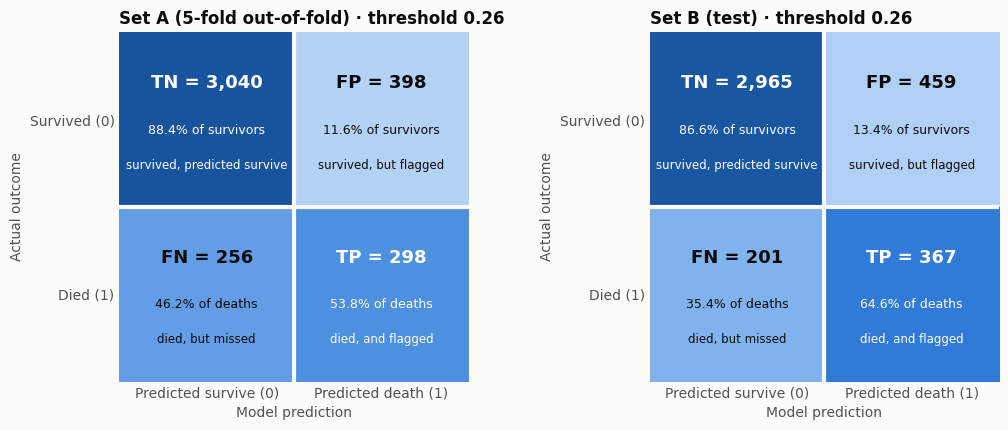

,Set A (5-fold out-of-fold),Set B (test)
AUROC,0.8438,0.8594
AUPRC,0.4761,0.5354
Brier score,0.0955,0.0899
Sensitivity (recall),0.5379,0.6461
Specificity,0.8842,0.8659
Precision (PPV),0.4282,0.4443
NPV,0.9223,0.9365
F1,0.4768,0.5265
Balanced accuracy,0.7111,0.7560
Accuracy,0.8362,0.8347


In [32]:
# P2 · Step 8: classification metrics. The decision threshold is chosen on Set A (out-of-fold predictions),
# then applied unchanged to Set B, so the test set never influences any choice.
from sklearn.metrics import (roc_curve, precision_recall_curve, confusion_matrix, f1_score,
                             balanced_accuracy_score, accuracy_score, brier_score_loss)
from matplotlib.colors import LinearSegmentedColormap

def oof_predictions(params: dict, X: pd.DataFrame, y: np.ndarray, seed: int) -> np.ndarray:
    """Out-of-fold probabilities on Set A: each patient is predicted by a model that never saw them."""
    oof = np.zeros(len(y))
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y):
        model = lgb.LGBMClassifier(**params, random_state=seed).fit(X.iloc[tr], y[tr])
        oof[va] = model.predict_proba(X.iloc[va])[:, 1]
    return oof

p_oof = oof_predictions(FINAL_PARAMS, X_train_tab, y_train, FINAL_SEED)

# Threshold = the one that maximises F1 on Set A out-of-fold predictions
prec, rec, thr = precision_recall_curve(y_train, p_oof)
f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
THRESHOLD = float(thr[np.argmax(f1)])
print(f"Decision threshold (max F1 on Set A out-of-fold): {THRESHOLD:.3f}")

# Confusion matrices: rows = what actually happened, columns = what the model predicted
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"])  # one hue, light -> dark
CELL_NAMES = [["TN", "FP"], ["FN", "TP"]]
CELL_MEANING = [["survived, predicted survive", "survived, but flagged"], ["died, but missed", "died, and flagged"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), facecolor=SURFACE)
for ax, (title, y, p) in zip(axes, [("Set A (5-fold out-of-fold)", y_train, p_oof), ("Set B (test)", y_test, p_test)]):
    cm = confusion_matrix(y, (p >= THRESHOLD).astype(int), labels=[0, 1])
    rate = cm / cm.sum(axis=1, keepdims=True)                       # share of each actual class
    ax.imshow(rate, cmap=BLUES, vmin=0, vmax=1)
    for k in (0.5,):                                                # 2px surface gap between cells
        ax.axhline(k, color=SURFACE, linewidth=3); ax.axvline(k, color=SURFACE, linewidth=3)
    for i in range(2):
        for j in range(2):
            ink = "#ffffff" if rate[i, j] > 0.5 else INK
            ax.text(j, i - 0.18, f"{CELL_NAMES[i][j]} = {cm[i, j]:,}", ha="center", color=ink, fontsize=13, fontweight="bold")
            ax.text(j, i + 0.08, f"{rate[i, j]:.1%} of {'survivors' if i == 0 else 'deaths'}", ha="center", color=ink, fontsize=9)
            ax.text(j, i + 0.28, CELL_MEANING[i][j], ha="center", color=ink, fontsize=8.5)
    ax.set_xticks([0, 1], ["Predicted survive (0)", "Predicted death (1)"], color=INK_2)
    ax.set_yticks([0, 1], ["Survived (0)", "Died (1)"], color=INK_2)
    ax.set_xlabel("Model prediction", color=INK_2); ax.set_ylabel("Actual outcome", color=INK_2)
    ax.tick_params(length=0); ax.spines[:].set_visible(False)
    ax.set_title(f"{title} · threshold {THRESHOLD:.2f}", loc="left", color=INK, fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "p2_confusion_matrices.png", dpi=200, facecolor=SURFACE)
plt.show()

def classification_report_at(y: np.ndarray, p: np.ndarray, threshold: float) -> dict:
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "AUROC": roc_auc_score(y, p), "AUPRC": average_precision_score(y, p),
        "Brier score": brier_score_loss(y, p),                     # calibration + sharpness (lower is better)
        "Sensitivity (recall)": tp / (tp + fn), "Specificity": tn / (tn + fp),
        "Precision (PPV)": tp / (tp + fp) if tp + fp else np.nan, "NPV": tn / (tn + fn) if tn + fn else np.nan,
        "F1": f1_score(y, pred), "Balanced accuracy": balanced_accuracy_score(y, pred),
        "Accuracy": accuracy_score(y, pred), "TP": tp, "FP": fp, "TN": tn, "FN": fn,
    }

metrics = pd.DataFrame({
    "Set A (5-fold out-of-fold)": classification_report_at(y_train, p_oof, THRESHOLD),
    "Set B (test)":               classification_report_at(y_test, p_test, THRESHOLD),
})
display(metrics.style.format(lambda v: f"{v:.0f}" if float(v).is_integer() and v > 1 else f"{v:.4f}"))

Here, we have some metrics calculated from the model that use `THRESHOLD = 0.26`. The threshold is decided by maximixing F1 score, that is aligning precision with recall.

In [33]:
# P2 · Step 9: how does the choice of threshold change the trade-off? Each rule picks its threshold on
# Set A out-of-fold predictions; the same threshold is then applied to Set B.
fpr_a, tpr_a, thr_roc = roc_curve(y_train, p_oof)
f2 = 5 * prec[:-1] * rec[:-1] / np.clip(4 * prec[:-1] + rec[:-1], 1e-12, None)
threshold_rules = {
    "Max F1 (precision = recall weight)":   THRESHOLD,
    "Max F2 (recall weighted 2x)":          float(thr[np.argmax(f2)]),
    "Youden J (max sensitivity + specificity)": float(thr_roc[np.argmax(tpr_a - fpr_a)]),
    "Sensitivity >= 90% on Set A":          float(thr_roc[np.argmax(tpr_a >= 0.90)]),
    "Alert budget: top 15% of patients":    float(np.quantile(p_oof, 0.85)),
}

def operating_point(y: np.ndarray, p: np.ndarray, t: float) -> dict:
    pred = p >= t
    tp, fp = int((pred & (y == 1)).sum()), int((pred & (y == 0)).sum())
    fn, tn = int((~pred & (y == 1)).sum()), int((~pred & (y == 0)).sum())
    return {"Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp), "PPV": tp / max(tp + fp, 1),
            "NPV": tn / max(tn + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "Flagged %": pred.mean(), "Flags per death caught": (tp + fp) / max(tp, 1),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

rows = [{"rule": rule, "threshold": t, **operating_point(y_test, p_test, t)} for rule, t in threshold_rules.items()]
op_table = pd.DataFrame(rows).set_index("rule")
print("Operating points on Set B (test), thresholds chosen on Set A:")
display(op_table.style.format({"threshold": "{:.3f}", "Sensitivity": "{:.1%}", "Specificity": "{:.1%}", "PPV": "{:.1%}",
                                "NPV": "{:.1%}", "F1": "{:.3f}", "Flagged %": "{:.1%}", "Flags per death caught": "{:.2f}"}))

Operating points on Set B (test), thresholds chosen on Set A:


,threshold,Sensitivity,Specificity,PPV,NPV,F1,Flagged %,Flags per death caught,TP,FP,FN,TN
rule,,,,,,,,,,,,
Max F1 (precision = recall weight),0.259,64.6%,86.6%,44.4%,93.7%,0.527,20.7%,2.25,367,459,201,2965
Max F2 (recall weighted 2x),0.087,86.8%,68.0%,31.0%,96.9%,0.457,39.8%,3.23,493,1097,75,2327
Youden J (max sensitivity + specificity),0.101,84.7%,70.8%,32.5%,96.5%,0.469,37.1%,3.08,481,1000,87,2424
Sensitivity >= 90% on Set A,0.053,91.7%,58.1%,26.6%,97.7%,0.413,49.0%,3.75,521,1435,47,1989
Alert budget: top 15% of patients,0.300,60.7%,88.9%,47.7%,93.2%,0.534,18.1%,2.10,345,379,223,3045


We can see that each method for defining threshold answers different use case.
1. Max F1 provides low sensitivity (64.6%) but high specificity (86.6%). Max F1 suits limited resources: fewer flags, and a higher share of flagged patients actually die (PPV 44%).
2. Max F2 tries to put more weight (up to 2x) on recall, leading to higher sensitivity (86.8%) but lower specificity (68%) compare to Max F1. F2 favours catching deaths.
3. Youden maximises sensitivity + specificity − 1, the sum, not each one separately. It picks the point on the ROC curve furthest from the chance diagonal.
4. Sensitivity ≥ 90%: catches 91.7% of deaths, but flags 49% of patients, with about 3.8 flags per death caught. It suits a "never miss" screening goal, at a cost of many false alarms.
5. Alert budget, top 15%: flags about 18% of patients with the highest PPV (47.7%). It suits a fixed number of beds or staff who can review cases.

Which rule fits your intended clinical use? There's no single right answer.

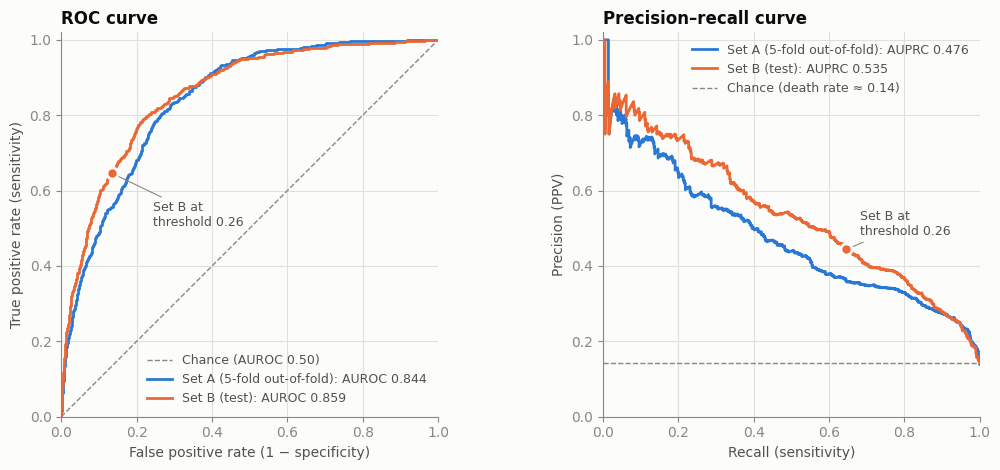

In [34]:
# P2 · Step 10: ROC and precision-recall curves, Set A out-of-fold vs Set B test, side by side
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SERIES = {"Set A (5-fold out-of-fold)": ("#2a78d6", y_train, p_oof),     # categorical slot 1 (blue)
          "Set B (test)":               ("#eb6834", y_test,  p_test)}    # categorical slot 2 (orange)

plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK_2,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK})
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.8), facecolor=SURFACE)

for ax in (ax_roc, ax_pr):
    ax.set_facecolor(SURFACE)
    ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.set_aspect("equal")

# ROC: chance = diagonal
ax_roc.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--", label="Chance (AUROC 0.50)")
for name, (color, y, p) in SERIES.items():
    fpr, tpr, _ = roc_curve(y, p)
    ax_roc.plot(fpr, tpr, color=color, linewidth=2, label=f"{name}: AUROC {roc_auc_score(y, p):.3f}")
ax_roc.set_xlabel("False positive rate (1 − specificity)"); ax_roc.set_ylabel("True positive rate (sensitivity)")
ax_roc.set_title("ROC curve", loc="left", color=INK, fontweight="bold")

# Precision-recall: chance = the death rate of each set
for name, (color, y, p) in SERIES.items():
    pr_p, pr_r, _ = precision_recall_curve(y, p)
    ax_pr.plot(pr_r, pr_p, color=color, linewidth=2, label=f"{name}: AUPRC {average_precision_score(y, p):.3f}")
ax_pr.axhline(y_test.mean(), color=MUTED, linewidth=1, linestyle="--",
              label=f"Chance (death rate ≈ {y_test.mean():.2f})")
ax_pr.set_xlabel("Recall (sensitivity)"); ax_pr.set_ylabel("Precision (PPV)")
ax_pr.set_title("Precision–recall curve", loc="left", color=INK, fontweight="bold")

# Mark the chosen threshold on each test curve
pred = p_test >= THRESHOLD
tpr_t, fpr_t = pred[y_test == 1].mean(), pred[y_test == 0].mean()
ppv_t = y_test[pred].mean()
for ax, (x, yv), offset in ((ax_roc, (fpr_t, tpr_t), (30, -38)), (ax_pr, (tpr_t, ppv_t), (10, 10))):
    ax.plot(x, yv, "o", markersize=8, color="#eb6834", markeredgecolor=SURFACE, markeredgewidth=2, zorder=5)
    ax.annotate(f"Set B at\nthreshold {THRESHOLD:.2f}", (x, yv), xytext=offset, textcoords="offset points",
                color=INK_2, fontsize=9,      # placed in the empty area beside the curve
                arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8, shrinkA=2, shrinkB=5))

for ax in (ax_roc, ax_pr):
    ax.legend(loc="lower right" if ax is ax_roc else "upper right", frameon=False, fontsize=9, labelcolor=INK_2)
fig.tight_layout()
fig.savefig(OUT_DIR / "p2_roc_pr_curves.png", dpi=200, facecolor=SURFACE)
plt.show()

On both of the pictures, we can see that both curves lie far above the chance lines. We also know that the Set B and Set A curves are close, means that the performance holds on new patients. We also use `THRESHOLD = 0.26`, marked by the dot.

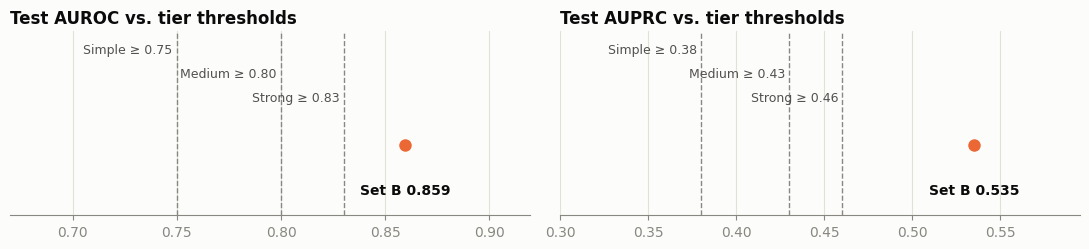

In [35]:
# P2 · Step 11: test result vs the baseline tiers - one panel per metric (separate scales, no dual axis)
tiers = pd.DataFrame(TIERS, columns=["tier", "AUROC", "AUPRC"]).set_index("tier").loc[["Simple", "Medium", "Strong"]]
results = {"AUROC": test_auroc, "AUPRC": test_auprc}

fig, axes = plt.subplots(1, 2, figsize=(11, 2.6), facecolor=SURFACE)
for ax, metric in zip(axes, ["AUROC", "AUPRC"]):
    ax.set_facecolor(SURFACE); ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    lo = tiers[metric].min() - 0.08
    ax.set_xlim(lo, max(results[metric], tiers[metric].max()) + 0.06); ax.set_ylim(-0.7, 0.6); ax.set_yticks([])
    for row, (tier, value) in enumerate(tiers[metric].items()):          # stagger labels so close tiers don't collide
        ax.axvline(value, color=MUTED, linewidth=1, linestyle="--")
        ax.text(value - 0.002, 0.45 - 0.17 * row, f"{tier} ≥ {value:.2f}", ha="right", color=INK_2, fontsize=9)
    ax.plot(results[metric], -0.2, "o", markersize=11, color="#eb6834", markeredgecolor=SURFACE, markeredgewidth=2, zorder=5)
    ax.text(results[metric], -0.55, f"Set B {results[metric]:.3f}", ha="center", color=INK, fontsize=10, fontweight="bold")
    ax.set_title(f"Test {metric} vs. tier thresholds", loc="left", color=INK, fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "p2_tiers.png", dpi=200, facecolor=SURFACE)
plt.show()

Our model has fulfill the requirement for achieving a strong result. AUROC is 0.859 against 0.83 (+0.029), AUPRC 0.535 against 0.46 (+0.075). Both must clear the cut-off, and both do.

In [36]:
# P2 · Step 12: save the final model (+ what is needed to reuse it), then reload it and check the predictions match
import json, joblib
MODEL_DIR = OUT_DIR / "model"; MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(final_model, MODEL_DIR / f"{STUDENT_ID}_lgbm_final.joblib")            # full scikit-learn wrapper
final_model.booster_.save_model(str(MODEL_DIR / f"{STUDENT_ID}_lgbm_final.txt"))     # LightGBM native text format
model_card = {
    "model": "LightGBM LGBMClassifier", "seed": FINAL_SEED, "params": FINAL_PARAMS,
    "trained_on": f"Set A, {len(y_train)} patients", "prediction_hour": ANCHOR, "input_window_h": [0, ANCHOR],
    "decision_threshold": THRESHOLD, "threshold_rule": "max F1 on Set A 5-fold out-of-fold predictions",
    "test_auroc": round(test_auroc, 4), "test_auprc": round(test_auprc, 4), "tier": tier,
    "feature_columns": list(X_train_tab.columns),                     # input order expected by the model
    "versions": {"lightgbm": lgb.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
(MODEL_DIR / f"{STUDENT_ID}_lgbm_final.json").write_text(json.dumps(model_card, indent=2, default=float), encoding="utf-8")

# Reload check: both saved formats must reproduce the test predictions exactly
reloaded = joblib.load(MODEL_DIR / f"{STUDENT_ID}_lgbm_final.joblib")
booster = lgb.Booster(model_file=str(MODEL_DIR / f"{STUDENT_ID}_lgbm_final.txt"))
assert np.allclose(reloaded.predict_proba(X_test_tab)[:, 1], p_test)
assert np.allclose(booster.predict(X_test_tab), p_test)
print("Saved and verified:")
for f in sorted(MODEL_DIR.iterdir()):
    print(f"  {f.name:32s} {f.stat().st_size / 1024:8.1f} KB")

Saved and verified:
  R15H45018_lgbm_final.joblib        2619.4 KB
  R15H45018_lgbm_final.json             6.8 KB
  R15H45018_lgbm_final.txt           2617.3 KB


The model is saved in 2 formats with a description file, and reloading reproduces the predictions exactly.

In [37]:
# P2 · Step 13: inference test - predict for patients straight from their raw .txt files, using only the saved files
import time
card = json.loads((MODEL_DIR / f"{STUDENT_ID}_lgbm_final.json").read_text(encoding="utf-8"))
deployed = joblib.load(MODEL_DIR / f"{STUDENT_ID}_lgbm_final.joblib")

def predict_from_raw(files: list[Path]) -> pd.DataFrame:
    """raw file -> 2 h bins (provided code) -> 0-36 h summaries -> risk. The outcome is unknown at prediction time,
    so a placeholder label is passed to process_patient; make_features never uses it."""
    rows = []
    for f in files:
        pid = int(f.stem)
        wide = p12.process_patient(f, pd.Series({pid: -1}))                      # -1 = unknown outcome
        X_new = make_features(wide).reindex(columns=card["feature_columns"])     # same columns, same order as training
        risk = float(deployed.predict_proba(X_new)[:, 1][0])
        rows.append({"pid": pid, "predicted risk": risk, "flagged": risk >= card["decision_threshold"]})
    return pd.DataFrame(rows).set_index("pid")

# Demo: 3 survivors and 3 deaths drawn at random from Set B (inference only - nothing is trained or tuned here)
rng = np.random.default_rng(FINAL_SEED)
demo_pids = np.concatenate([rng.choice(PIDS_B[y_test == 0], 3, replace=False), rng.choice(PIDS_B[y_test == 1], 3, replace=False)])
t0 = time.perf_counter()
demo = predict_from_raw([SET_B_DIR / f"{pid}.txt" for pid in demo_pids])
elapsed_ms = (time.perf_counter() - t0) / len(demo_pids) * 1000

# Checks: the raw-file route gives exactly the same risk as Step 7, and show the true outcome next to it
assert np.allclose(demo["predicted risk"], pd.Series(p_test, index=PIDS_B).loc[demo.index]), "inference differs from Step 7"
demo["actual outcome"] = outcomes_b.loc[demo.index].map({0: "survived", 1: "died"})
demo["result"] = np.select([demo["flagged"] & (demo["actual outcome"] == "died"), demo["flagged"],
                            demo["actual outcome"] == "died"], ["TP", "FP", "FN"], default="TN")
print(f"Model: {card['model']} | threshold {card['decision_threshold']:.3f} | {elapsed_ms:.0f} ms per patient (raw file -> risk)")
display(demo.style.format({"predicted risk": "{:.3f}"}))

Model: LightGBM LGBMClassifier | threshold 0.259 | 56 ms per patient (raw file -> risk)


,predicted risk,flagged,actual outcome,result
pid,,,,
149307,0.232,False,survived,TN
143559,0.420,True,survived,FP
150536,0.109,False,survived,TN
143490,0.094,False,died,FN
149870,0.157,False,died,FN
151369,0.747,True,died,TP


The inference test predicts from raw files with no label and matches Step 7. At 6 patients it's a working demo, not an evaluation.

In summary:

1. Final numbers
- Test (Set B): AUROC 0.8594, AUPRC 0.5354, Strong tier.
- Cross-validation on Set A, for context: 0.8465 ± 0.0019 / 0.4815 ± 0.0046.

2. Seeds
- Final model: FINAL_SEED = 42, set in cell 0 of the notebook.
- All seeds tried (homework rule 4): 42, 7 and 2024 for cross-validation in Steps 2–6, and 42 for Step 7. Every run is in outputs/seed_log.csv.

3. Code
- The notebook: hw1_R15H45018.ipynb, P2 Steps 1–13.
- Required files: the provided P12_preprocess.py, and the data (set-a, set-b, Outcomes-a.txt, Outcomes-b.txt).
- Environment: Python and library versions, especially LightGBM (4.7.0 locally).

4. Command
- Set B (test): AUROC 0.8594 | AUPRC 0.5354 → tier: Strong
- P1 until P2 runtime: 27 m 34 s.

## P3 · Open exploration

**Question**:
Is the predictive utility of the first 12 ICU hours consistent across all specialties, or does it vary depending on why a patient is admitted? For example, does this value diminish in cardiac surgery cases where early metrics primarily reflect anaesthetic effects rather than physiological compromise?

In P2, we ask whether hours 0-12 help **on average** an choose a window. P3 asks **for whom** they help, and why.

**Approach**

Hypothesis: Cardiac Surgery Recovery (CSRU) is expected to gain least while Coronary Care (CCU) is expected to gain the most in the first 12 ICU hours data table. For CSRU, the early data mostly reflects the operation they just had, leading to hours 0-12 are mostly **procedural noise**. For CCU, the early data mostly reflects the disease that brought them in, leading to **physiological reflection** of how severe the disease was.

Model:
Train P2's model with each window (12–36 h vs 0–36 h) on all patients, including `ICUType` as an input. We will find the effect on Set A, then check it on Set B. Then compute AUROC per ICU type and the gain (0–36 minus 12–36). Separate models per ICU type would be too data-poor (43 CSRU deaths). We will use AUROC as the main metric because AUPRC is not comparable across ICU types.

Set A - ICU type profile (patients kept in P1(f)):


,patients,deaths,mortality %,median age,GCS 0-12 h,GCS 12-36 h,ventilated % 0-12 h,ventilated % 12-36 h,labs per bin 0-12 h,labs per bin 12-36 h,coverage gain from 0-12 h (pp)
Coronary Care (CCU),575,81,14.1,73,12.4,12.2,35.0,41.9,2.2,1.4,9.8
Cardiac Surgery Recovery (CSRU),874,43,4.9,70,8.8,12.3,86.6,70.9,1.7,1.2,5.6
Medical ICU (MICU),1476,275,18.6,64,11.4,11.6,44.8,48.5,2.4,1.5,7.8
Surgical ICU (SICU),1067,155,14.5,63,10.4,11.0,61.0,63.6,2.5,1.5,6.2


Set B - size and outcome per ICU type:


,patients,deaths,mortality %
Coronary Care (CCU),587,72,12.3
Cardiac Surgery Recovery (CSRU),780,34,4.4
Medical ICU (MICU),1434,286,19.9
Surgical ICU (SICU),1191,176,14.8


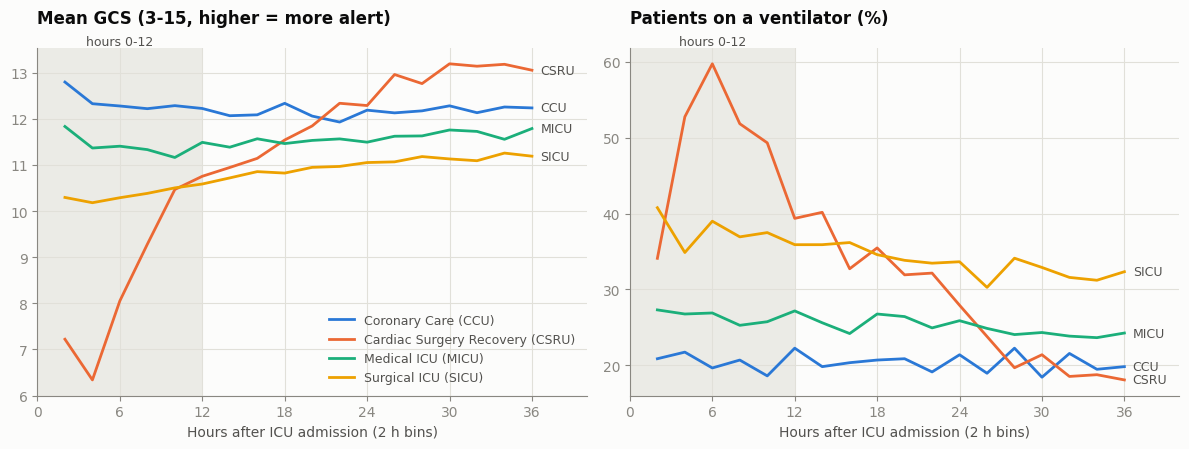

In [38]:
# P3 · Step 1: who is in each ICU type, and how do their first 12 hours differ? (descriptive only - no model yet)
ICU_NAMES = {1: "Coronary Care (CCU)", 2: "Cardiac Surgery Recovery (CSRU)", 3: "Medical ICU (MICU)", 4: "Surgical ICU (SICU)"}
ICU_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", 4: "#eda100"}       # categorical slots 1-4, fixed per ICU type
LABS = ["Creatinine", "BUN", "Glucose", "WBC", "Platelets", "HCT", "K", "Na", "Mg", "HCO3", "Lactate"]

def icu_profile(wide: pd.DataFrame, pids) -> pd.DataFrame:
    """One row per ICU type: size, outcome, and how the early (0-12 h) period differs from 12-36 h."""
    w = clean_codes(wide[wide["pid"].isin(pids) & (wide["timestamp"] <= ANCHOR)])
    early, later = w[w["timestamp"] <= WINDOW_START], w[w["timestamp"] > WINDOW_START]
    per_patient = w.groupby("pid")[["ICUType", "Age", "target"]].first()
    rows = {}
    for t, grp in per_patient.groupby("ICUType"):
        ids = grp.index
        e, l = early[early["pid"].isin(ids)], later[later["pid"].isin(ids)]
        cov = lambda win: win.groupby("pid")[DYN_P2].count().gt(0).reindex(ids, fill_value=False).mean()
        rows[ICU_NAMES[int(t)]] = {
            "patients": len(ids), "deaths": int(grp["target"].sum()), "mortality %": grp["target"].mean() * 100,
            "median age": grp["Age"].median(),
            "GCS 0-12 h": e["GCS"].mean(), "GCS 12-36 h": l["GCS"].mean(),                      # sedation shows as low early GCS
            "ventilated % 0-12 h": e.groupby("pid")["MechVent"].max().reindex(ids).notna().mean() * 100,
            "ventilated % 12-36 h": l.groupby("pid")["MechVent"].max().reindex(ids).notna().mean() * 100,
            "labs per bin 0-12 h": e[LABS].notna().sum(axis=1).mean(), "labs per bin 12-36 h": l[LABS].notna().sum(axis=1).mean(),
            "coverage gain from 0-12 h (pp)": ((cov(w) - cov(l)) * 100).mean(),               # avg over 36 variables
        }
    return pd.DataFrame(rows).T

profile_a = icu_profile(wide_a, PIDS_A)
print("Set A - ICU type profile (patients kept in P1(f)):")
display(profile_a.style.format({c: "{:.0f}" for c in ["patients", "deaths", "median age"]} |
                               {c: "{:.1f}" for c in profile_a.columns if c not in ["patients", "deaths", "median age"]}))
profile_b = icu_profile(wide_b, PIDS_B)[["patients", "deaths", "mortality %"]]
print("Set B - size and outcome per ICU type:")
display(profile_b.style.format({"patients": "{:.0f}", "deaths": "{:.0f}", "mortality %": "{:.1f}"}))

# Figure: GCS and ventilation over the first 36 h, per ICU type (one panel per measure - separate scales, no dual axis)
w_a = clean_codes(wide_a[wide_a["pid"].isin(PIDS_A) & (wide_a["timestamp"] <= ANCHOR)])
n_per_type = w_a.groupby("ICUType")["pid"].nunique()
series = {
    "Mean GCS (3-15, higher = more alert)": w_a.groupby(["ICUType", "timestamp"])["GCS"].mean().unstack(0),
    "Patients on a ventilator (%)": (w_a.groupby(["ICUType", "timestamp"])["MechVent"].count().unstack(0) / n_per_type * 100),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), facecolor=SURFACE)
for ax, (title, table) in zip(axes, series.items()):
    ax.set_facecolor(SURFACE); ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    ax.axvspan(0, WINDOW_START, color=GRID, alpha=0.6, linewidth=0)                       # the early period in question
    ax.text(WINDOW_START / 2, 1.0, "hours 0-12", transform=ax.get_xaxis_transform(), ha="center", va="bottom",
            color=INK_2, fontsize=9)
    for t in sorted(table.columns):
        ax.plot(table.index, table[t], color=ICU_COLORS[int(t)], linewidth=2, label=ICU_NAMES[int(t)])
        ax.annotate(ICU_NAMES[int(t)].split("(")[1].rstrip(")"), (table.index[-1], table[t].iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)    # direct label
    ax.set_xlim(0, ANCHOR + 4); ax.set_xticks(range(0, ANCHOR + 1, 6))
    ax.set_xlabel("Hours after ICU admission (2 h bins)", color=INK_2)
    ax.set_title(title, loc="left", color=INK, fontweight="bold", pad=18)
axes[0].legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK_2)
fig.tight_layout()
fig.savefig(OUT_DIR / "p3_icu_types_first_36h.png", dpi=200, facecolor=SURFACE)
plt.show()

We have 4 types of ICU event: Coronary Care (CCU), Cardiac Surgery Recovery (CSRU), Medical ICU (MICU), and Surgical ICU (SICU). Here, we assess the `GCS` and `ventilated` for each events. We see that in `GCS`, CSRU shows the least value and the graphic shows lower value before hour 12. In `ventilated`, CSRU shwos the most value by having spikes at around hour 6 for up to 60%.

When we look at the mortality rate for each event, CSRU is the least with 4.9% while MICU is the most with 18.6%.

In [39]:
# P3 · Step 2: discovery on Set A - AUROC per ICU type with the 12-36 h vs 0-36 h window.
# One pooled model per window (final P2 settings, ICUType is an input), out-of-fold predictions, 3 seeds.
icu_a = X_train_tab["ICUType"].astype(int).to_numpy()            # ICU type of each Set A patient (same order as y_train)
windows_a = {"12-36 h": X_12_36, "0-36 h": X_train_tab}           # X_12_36 was built in P2 Step 2

oof = {w: {} for w in windows_a}                                  # oof[window][seed] = out-of-fold probabilities
for w, X in windows_a.items():
    for s in SEEDS_CV:
        oof[w][s] = oof_predictions(FINAL_PARAMS, X, y_train, s)  # oof_predictions from P2 Step 8
        log_seed(s, f"P3-CV window {w} (out-of-fold, for per-ICU AUROC)",
                 cv_auroc=round(roc_auc_score(y_train, oof[w][s]), 4))

def auroc_by_icu(y, p, icu) -> dict:
    out = {ICU_NAMES[t]: roc_auc_score(y[icu == t], p[icu == t]) for t in sorted(ICU_NAMES)}
    out["All patients"] = roc_auc_score(y, p)
    return out

rows = []
for s in SEEDS_CV:
    a12, a0 = auroc_by_icu(y_train, oof["12-36 h"][s], icu_a), auroc_by_icu(y_train, oof["0-36 h"][s], icu_a)
    rows += [{"seed": s, "group": g, "AUROC 12-36 h": a12[g], "AUROC 0-36 h": a0[g], "gain": a0[g] - a12[g]} for g in a0]
per_seed_a = pd.DataFrame(rows)
summary_a = per_seed_a.groupby("group", sort=False).agg(
    **{"AUROC 12-36 h": ("AUROC 12-36 h", "mean"), "AUROC 0-36 h": ("AUROC 0-36 h", "mean"),
       "gain (mean)": ("gain", "mean"), "gain (sd over seeds)": ("gain", "std")})
summary_a.insert(0, "deaths", [int(y_train[icu_a == t].sum()) for t in sorted(ICU_NAMES)] + [int(y_train.sum())])

print("Set A, 5-fold out-of-fold AUROC per ICU type (mean over 3 seeds):")
display(summary_a.style.format({"deaths": "{:.0f}", "AUROC 12-36 h": "{:.4f}", "AUROC 0-36 h": "{:.4f}",
                                "gain (mean)": "{:+.4f}", "gain (sd over seeds)": "{:.4f}"}))

Set A, 5-fold out-of-fold AUROC per ICU type (mean over 3 seeds):


,deaths,AUROC 12-36 h,AUROC 0-36 h,gain (mean),gain (sd over seeds)
group,,,,,
Coronary Care (CCU),81,0.8443,0.8445,+0.0002,0.0076
Cardiac Surgery Recovery (CSRU),43,0.8716,0.9021,+0.0305,0.0019
Medical ICU (MICU),275,0.7905,0.7998,+0.0094,0.0042
Surgical ICU (SICU),155,0.8361,0.8435,+0.0073,0.0068
All patients,554,0.8373,0.8465,+0.0093,0.0023


Here, we try to find the AUROC based on the ICU types.To find the AUROC and the gain, we use P2's final model and we train once per window (12-36 h and 0-36 h), out of fold, 3 seeds. What is surprising is that CSRU shows significant gain (+0.031) when we use the data from 0-36 hour. Compare to CCU, it shows the least gain (+0.000). From this experiment, **the result goes against the hypothesis** and leave significance to Step 3.

In [40]:
# P3 · Step 3: is the gain real, and does it differ between ICU types? Paired bootstrap on Set A.
# Each resample draws patients with replacement (within each ICU type) and scores BOTH windows on the same patients.
N_BOOT = 1000

def bootstrap_gain(y, p_new, p_old, icu, n_boot=N_BOOT, seed=FINAL_SEED) -> tuple[pd.DataFrame, dict]:
    rng = np.random.default_rng(seed)
    idx = {t: np.where(icu == t)[0] for t in sorted(ICU_NAMES)}
    draws = {t: [] for t in idx}
    for _ in range(n_boot):
        for t, ii in idx.items():
            b = rng.choice(ii, len(ii))
            if y[b].min() == y[b].max():                          # a resample needs both survivors and deaths
                continue
            draws[t].append(roc_auc_score(y[b], p_new[b]) - roc_auc_score(y[b], p_old[b]))
    rows = {}
    for t, d in draws.items():
        d = np.array(d)
        rows[ICU_NAMES[t]] = {"gain": roc_auc_score(y[idx[t]], p_new[idx[t]]) - roc_auc_score(y[idx[t]], p_old[idx[t]]),
                              "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5),
                              "share of resamples with gain > 0": (d > 0).mean()}
    return pd.DataFrame(rows).T, {t: np.array(d) for t, d in draws.items()}

# Average the 3 seeds' out-of-fold predictions, so the bootstrap measures patient-sampling uncertainty
p12_a = np.mean([oof["12-36 h"][s] for s in SEEDS_CV], axis=0)
p0_a  = np.mean([oof["0-36 h"][s] for s in SEEDS_CV], axis=0)
boot_a, draws_a = bootstrap_gain(y_train, p0_a, p12_a, icu_a)
log_seed(FINAL_SEED, f"P3-bootstrap Set A ({N_BOOT} resamples)")

# Direct test of the hypothesis: is CCU's gain larger than CSRU's? (difference of the two bootstrap gains)
def contrast(draws: dict, hi: int = 1, lo: int = 2) -> dict:
    n = min(len(draws[hi]), len(draws[lo])); d = draws[hi][:n] - draws[lo][:n]
    return {"CCU gain - CSRU gain": d.mean(), "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5),
            "share of resamples > 0": (d > 0).mean()}

print(f"Set A - gain in AUROC from adding hours 0-12 (0-36 h minus 12-36 h), paired bootstrap, {N_BOOT} resamples:")
display(boot_a.style.format({"gain": "{:+.4f}", "95% CI low": "{:+.4f}", "95% CI high": "{:+.4f}",
                             "share of resamples with gain > 0": "{:.1%}"}))
print("Hypothesis contrast on Set A:")
display(pd.DataFrame([contrast(draws_a)]).style.format({"CCU gain - CSRU gain": "{:+.4f}", "95% CI low": "{:+.4f}",
                                                         "95% CI high": "{:+.4f}", "share of resamples > 0": "{:.1%}"}))

Set A - gain in AUROC from adding hours 0-12 (0-36 h minus 12-36 h), paired bootstrap, 1000 resamples:


,gain,95% CI low,95% CI high,share of resamples with gain > 0
Coronary Care (CCU),+0.0003,-0.0214,+0.0211,51.8%
Cardiac Surgery Recovery (CSRU),+0.0292,+0.0069,+0.0568,99.9%
Medical ICU (MICU),+0.0089,-0.0034,+0.0220,91.8%
Surgical ICU (SICU),+0.0078,-0.0073,+0.0238,84.2%


Hypothesis contrast on Set A:


,CCU gain - CSRU gain,95% CI low,95% CI high,share of resamples > 0
0,-0.0287,-0.0636,+0.0025,3.9%


We try the case for uncertainty on set A. A paired bootstrap (1,000 resamples of patients, both windows scored on the same resample) gives a 95% confidence interval per ICU type. This amplifies the argument that our hypothesis fails.

In [41]:
# P3 · Step 4: independent check on Set B - train each window once on all of Set A, score Set B per ICU type.
# The 0-36 h model is the final P2 model (p_test); only the 12-36 h model is new.
X_12_36_test = make_features(wide_b[wide_b["timestamp"] >= WINDOW_START]).reindex(index=PIDS_B, columns=X_train_tab.columns)
model_12_36 = lgb.LGBMClassifier(**FINAL_PARAMS, random_state=FINAL_SEED).fit(X_12_36, y_train)
p12_b = model_12_36.predict_proba(X_12_36_test)[:, 1]
log_seed(FINAL_SEED, "P3-Set B window 12-36 h (trained on all of Set A)", test_auroc=round(roc_auc_score(y_test, p12_b), 4))

icu_b = X_test_tab["ICUType"].astype(int).to_numpy()
boot_b, draws_b = bootstrap_gain(y_test, p_test, p12_b, icu_b)
a12_b, a0_b = auroc_by_icu(y_test, p12_b, icu_b), auroc_by_icu(y_test, p_test, icu_b)
boot_b.insert(0, "AUROC 0-36 h", [a0_b[g] for g in boot_b.index])
boot_b.insert(0, "AUROC 12-36 h", [a12_b[g] for g in boot_b.index])
boot_b.insert(0, "deaths", [int(y_test[icu_b == t].sum()) for t in sorted(ICU_NAMES)])
log_seed(FINAL_SEED, f"P3-bootstrap Set B ({N_BOOT} resamples)")

print(f"Set B (models trained on Set A) - AUROC per ICU type and gain, paired bootstrap, {N_BOOT} resamples:")
print(f"  all patients: 12-36 h {a12_b['All patients']:.4f} | 0-36 h {a0_b['All patients']:.4f} | gain {a0_b['All patients'] - a12_b['All patients']:+.4f}")
display(boot_b.style.format({"deaths": "{:.0f}", "AUROC 12-36 h": "{:.4f}", "AUROC 0-36 h": "{:.4f}", "gain": "{:+.4f}",
                             "95% CI low": "{:+.4f}", "95% CI high": "{:+.4f}", "share of resamples with gain > 0": "{:.1%}"}))
print("Hypothesis contrast on Set B:")
display(pd.DataFrame([contrast(draws_b)]).style.format({"CCU gain - CSRU gain": "{:+.4f}", "95% CI low": "{:+.4f}",
                                                         "95% CI high": "{:+.4f}", "share of resamples > 0": "{:.1%}"}))

Set B (models trained on Set A) - AUROC per ICU type and gain, paired bootstrap, 1000 resamples:
  all patients: 12-36 h 0.8563 | 0-36 h 0.8594 | gain +0.0031


,deaths,AUROC 12-36 h,AUROC 0-36 h,gain,95% CI low,95% CI high,share of resamples with gain > 0
Coronary Care (CCU),72,0.8346,0.8309,-0.0036,-0.0257,+0.0182,34.8%
Cardiac Surgery Recovery (CSRU),34,0.8297,0.8630,+0.0333,-0.0065,+0.0842,93.4%
Medical ICU (MICU),286,0.8102,0.8089,-0.0013,-0.0137,+0.0101,40.0%
Surgical ICU (SICU),176,0.8791,0.8886,+0.0095,-0.0028,+0.0222,93.8%


Hypothesis contrast on Set B:


,CCU gain - CSRU gain,95% CI low,95% CI high,share of resamples > 0
0,-0.0375,-0.0905,+0.0101,7.3%


Using the final model in P2, we do independent check on Set B. Both windows trained once on all of Set A, then scored on Set B per ICU type, with the same bootstrap. The result here is pretty similar with what we have in Set A. CSRU again gains most (+0.033), but its interval now includes 0 [−0.007, +0.084]. MICU's gain disappears (+0.009 → −0.001), and the overall gain is only +0.003.

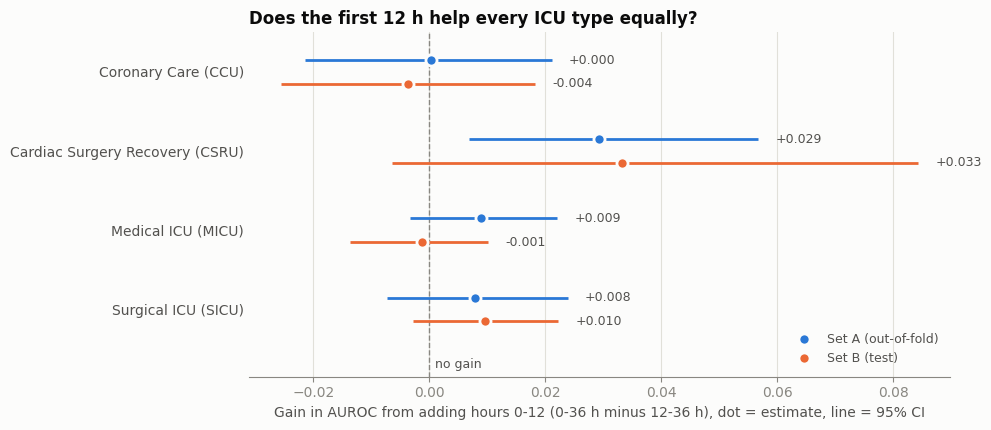

In [42]:
# P3 · Step 5: summary figure - gain from hours 0-12 per ICU type with 95% CI, Set A (discovery) vs Set B (check)
SET_COLORS = {"Set A (out-of-fold)": "#2a78d6", "Set B (test)": "#eb6834"}    # same set colours as P2
results = {"Set A (out-of-fold)": boot_a, "Set B (test)": boot_b}
order = [ICU_NAMES[t] for t in sorted(ICU_NAMES)]

fig, ax = plt.subplots(figsize=(10, 4.4), facecolor=SURFACE)
ax.set_facecolor(SURFACE); ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.axvline(0, color=MUTED, linewidth=1, linestyle="--")
ax.set_ylim(-0.85, len(order) - 0.5)
ax.text(0.001, -0.7, "no gain", ha="left", va="center", color=INK_2, fontsize=9)
for k, (name, res) in enumerate(results.items()):
    ys = np.arange(len(order))[::-1] + (0.15 if k == 0 else -0.15)
    r = res.loc[order]
    ax.hlines(ys, r["95% CI low"], r["95% CI high"], color=SET_COLORS[name], linewidth=2)
    ax.plot(r["gain"], ys, "o", markersize=8, color=SET_COLORS[name], markeredgecolor=SURFACE, markeredgewidth=2, label=name)
    for yv, (_, row) in zip(ys, r.iterrows()):
        ax.text(row["95% CI high"] + 0.003, yv, f"{row['gain']:+.3f}", va="center", color=INK_2, fontsize=9)
ax.set_yticks(np.arange(len(order))[::-1], order, color=INK_2); ax.tick_params(axis="y", length=0)
ax.set_xlabel("Gain in AUROC from adding hours 0-12 (0-36 h minus 12-36 h), dot = estimate, line = 95% CI", color=INK_2)
ax.set_title("Does the first 12 h help every ICU type equally?", loc="left", color=INK, fontweight="bold")
ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=INK_2)
fig.tight_layout()
fig.savefig(OUT_DIR / "p3_gain_by_icu_type.png", dpi=200, facecolor=SURFACE)
plt.show()

Here's the summary figure, saved in `p3_gain_by_icu_type.png`. It shows the gain per ICU type with its confidence interval, Set A in blue and Set B in orange.

The two-sided test (CCU minus CSRU) has intervals that just include 0 on both sets: Set A [−0.064, +0.003], Set B [−0.091, +0.010]. **So the hypothesis is not supported**, and the evidence points the opposite way, but the reversal isn't significant at 95%.

In [43]:
# P3 · Step 6 (post-hoc, exploratory): a possible "why" for the CSRU result. Not planned before seeing Steps 2-5,
# so it can suggest an explanation but cannot confirm one. No model - only mortality by simple early markers.
# Markers use only the bins BEFORE the 12-36 h window (hours 0-10), i.e. information only the 0-36 h model sees:
#   - GCS at hour 10: the last GCS value up to hour 10 (low = not yet awake/responsive)
#   - ventilated at hours 8-10: any MechVent record in the 8-10 h bin (still on the ventilator)
def early_markers(wide: pd.DataFrame, pids) -> pd.DataFrame:
    w = clean_codes(wide[wide["pid"].isin(pids) & (wide["timestamp"] < WINDOW_START)]).sort_values(["pid", "timestamp"])
    g = w.groupby("pid")
    late_vent = w[w["timestamp"] == WINDOW_START - p12.BIN_HOURS].groupby("pid")["MechVent"].count().reindex(g.size().index, fill_value=0)
    per = pd.DataFrame({"ICU type": g["ICUType"].first().astype(int).map(ICU_NAMES), "death": g["target"].first()})
    per["GCS at hour 10"] = pd.cut(g["GCS"].last(), [2, 8, 12, 15], labels=["3-8", "9-12", "13-15"])
    per["ventilated at hours 8-10"] = np.where(late_vent > 0, "yes", "no")
    return per

def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """95% Wilson confidence interval for a proportion - stable even for small groups."""
    if n == 0:
        return np.nan, np.nan
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def mortality_table(per: pd.DataFrame, marker: str) -> pd.DataFrame:
    rows = []
    for (icu, level), grp in per.dropna(subset=[marker]).groupby(["ICU type", marker], observed=True):
        k, n = int(grp["death"].sum()), len(grp)
        lo, hi = wilson(k, n)
        rows.append({"ICU type": icu, marker: level, "patients": n, "deaths": k,
                     "mortality": f"{k / n:.1%} [{lo:.1%}, {hi:.1%}]"})
    return pd.DataFrame(rows).set_index(["ICU type", marker])

markers_a, markers_b = early_markers(wide_a, PIDS_A), early_markers(wide_b, PIDS_B)
for marker in ["GCS at hour 10", "ventilated at hours 8-10"]:
    table = mortality_table(markers_a, marker).join(mortality_table(markers_b, marker), lsuffix=" (A)", rsuffix=" (B)")
    print(f"Mortality by '{marker}', per ICU type - Set A and Set B separately, 95% Wilson CI:")
    display(table)

Mortality by 'GCS at hour 10', per ICU type - Set A and Set B separately, 95% Wilson CI:


patients (A)  deaths (A)         mortality (A)  patients (B)  deaths (B)         mortality (B)
ICU type                        GCS at hour 10                                                                                                
Cardiac Surgery Recovery (CSRU) 3-8                      236          18    7.6% [4.9%, 11.7%]           214          17    7.9% [5.0%, 12.4%]
                                9-12                     288           4     1.4% [0.5%, 3.5%]           245           7     2.9% [1.4%, 5.8%]
                                13-15                    303          13     4.3% [2.5%, 7.2%]           275           5     1.8% [0.8%, 4.2%]
Coronary Care (CCU)             3-8                      112          36  32.1% [24.2%, 41.3%]           101          29  28.7% [20.8%, 38.2%]
                                9-12                      62          13  21.0% [12.7%, 32.6%]            62          11  17.7% [10.2%, 29.0%]
                                13-15                    389          29    7.5% [5.2%, 10.5%]           415          30    7.2% [5.1%, 10.1%]
Medical ICU (MICU)              3-8                      395          97  24.6% [20.6%, 29.0%]           345          92  26.7% [22.3%, 31.6%]
                                9-12                     276          53  19.2% [15.0%, 24.3%]           291          69  23.7% [19.2%, 28.9%]
                                13-15                    745         119  16.0% [13.5%, 18.8%]           739         112  15.2% [12.8%, 17.9%]
Surgical ICU (SICU)             3-8                      321          83  25.9% [21.4%, 30.9%]           347         101  29.1% [24.6%, 34.1%]
                                9-12                     316          36   11.4% [8.3%, 15.4%]           335          41   12.2% [9.2%, 16.2%]
                                13-15                    415          33    8.0% [5.7%, 11.0%]           492          32     6.5% [4.6%, 9.0%]

Mortality by 'ventilated at hours 8-10', per ICU type - Set A and Set B separately, 95% Wilson CI:


patients (A)  deaths (A)         mortality (A)  patients (B)  deaths (B)         mortality (B)
ICU type                        ventilated at hours 8-10                                                                                                
Cardiac Surgery Recovery (CSRU) no                                 443          25     5.6% [3.9%, 8.2%]           405          15     3.7% [2.3%, 6.0%]
                                yes                                431          18     4.2% [2.7%, 6.5%]           375          19     5.1% [3.3%, 7.8%]
Coronary Care (CCU)             no                                 468          52   11.1% [8.6%, 14.3%]           486          51   10.5% [8.1%, 13.5%]
                                yes                                107          29  27.1% [19.6%, 36.2%]           101          21  20.8% [14.0%, 29.7%]
Medical ICU (MICU)              no                                1096         188  17.2% [15.0%, 19.5%]          1053         194  18.4% [16.2%, 20.9%]
                                yes                                380          87  22.9% [19.0%, 27.4%]           381          92  24.1% [20.1%, 28.7%]
Surgical ICU (SICU)             no                                 667          79   11.8% [9.6%, 14.5%]           774          86   11.1% [9.1%, 13.5%]
                                yes                                400          76  19.0% [15.5%, 23.1%]           417          90  21.6% [17.9%, 25.8%]

What these numbers suggest:

- **In CSRU, not being responsive by hour 10 goes with roughly 2–4× higher mortality (about 8% vs 2–4%), on both sets**. The idea that slow recovery after surgery carries signal fits this.
- **In CSRU, being on a ventilator at hours 8–10 is not informative**. Almost half the patients still are, and mortality barely differs. In the other ICU types, it goes with clearly higher mortality.
- **Early GCS signals risk in every ICU type**, so the CSRU pattern isn't unique in direction. But the CSRU groups are tiny (13–18 deaths in some groups), and the CSRU 9–12 vs 13–15 order isn't consistent across the two sets

Final runtime: 33 m 13 s.